In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --
EPOCH: 1/5


3it [00:00, 83.36it/s]               


Time: 0m 0s | loss: 0.0368

EPOCH: 2/5


3it [00:00, 68.54it/s]               


Time: 0m 0s | loss: 0.0303

EPOCH: 3/5


3it [00:00, 99.87it/s]               


... (952 outputs left out)

1it [00:00, 74.14it/s]


Time: 0m 0s | loss: 0.0064

Training time: 0m 0s


1it [00:00, 464.18it/s]


Number of memories 20
Mem 0 has lenght of 20
Mem 1 has lenght of 20
Mem 2 has lenght of 20
Mem 3 has lenght of 20
Mem 4 has lenght of 20
Mem 5 has lenght of 20
Mem 6 has lenght of 20
Mem 7 has lenght of 20
Mem 8 has lenght of 20
Mem 9 has lenght of 20
Mem 10 has lenght of 20
Mem 11 has lenght of 20
Mem 12 has lenght of 20
Mem 13 has lenght of 20
Mem 14 has lenght of 20
Mem 15 has lenght of 20
Mem 16 has lenght of 20
Mem 17 has lenght of 20
Mem 18 has lenght of 20
Mem 19 has lenght of 20
Total memory length is 400
F1 Macro (Low freq): 0.0000
F1 Macro (Mid freq): 0.0000
F1 Macro (High freq): 0.0346


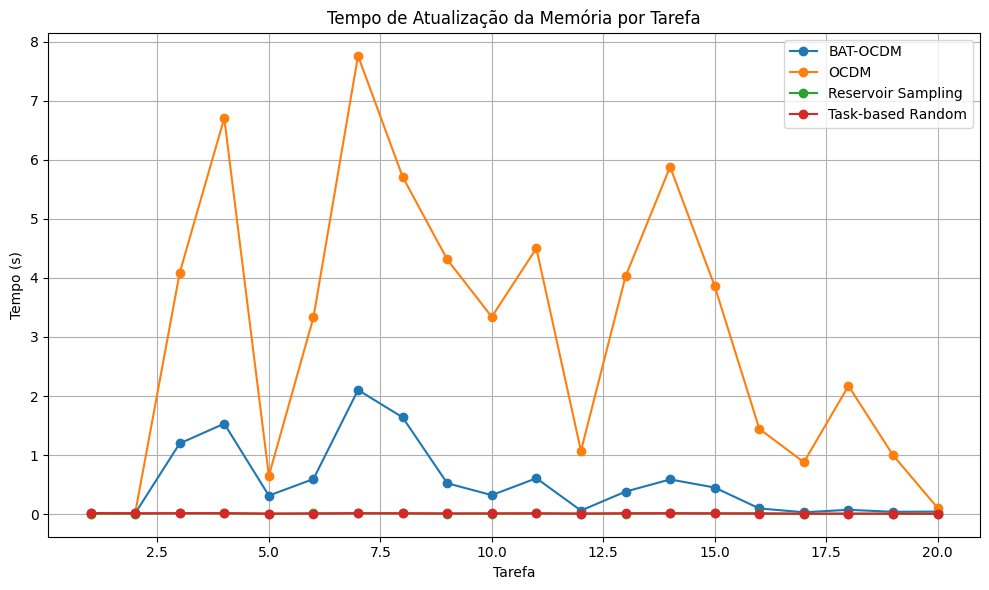

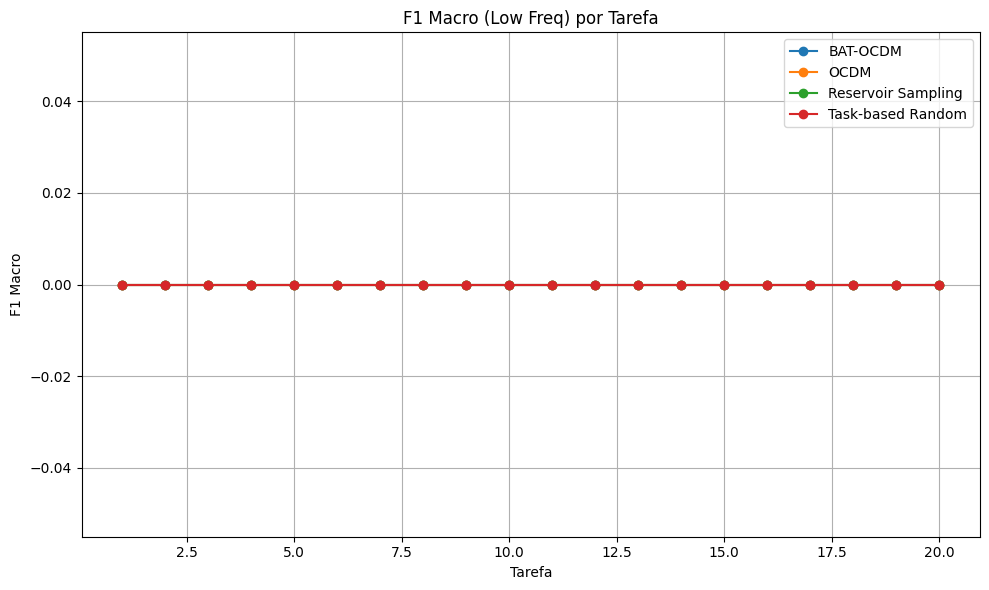

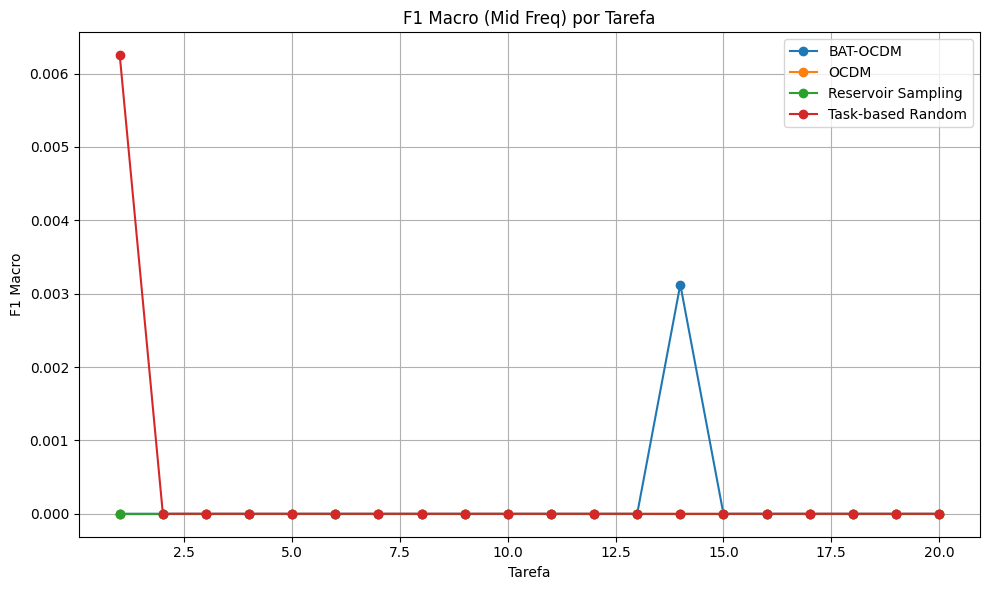

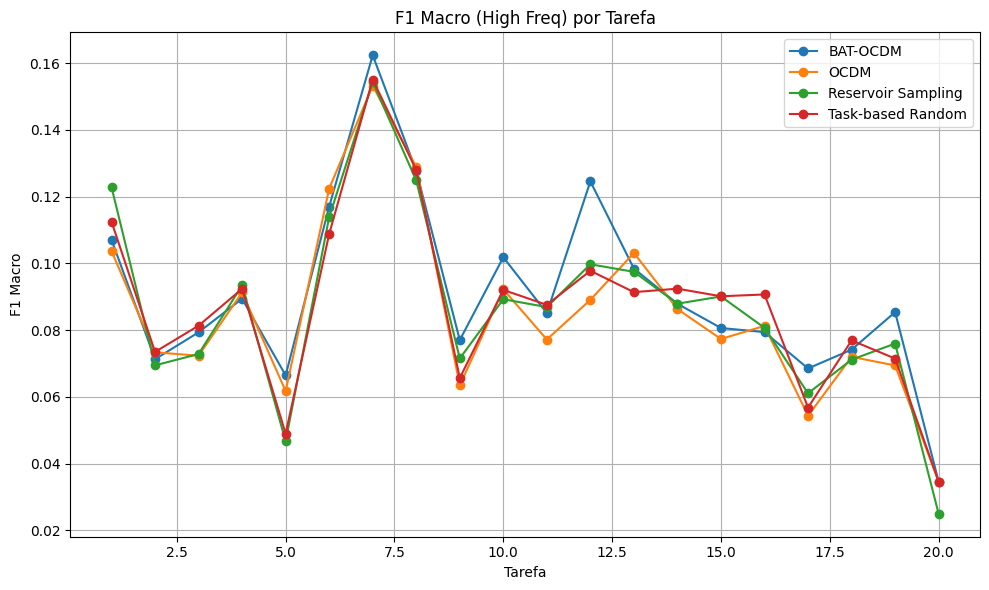

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo = 0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        '''Reduced baseline model: feed-forward NN without sequential layers'''
        if alarm_num_out is None:
            alarm_num_out = alarm_num_in
        if 'hp_activation' in hparams.keys():
            activation = hparams['hp_activation']
        else:
            warnings.warn('Warning! Using default value for activation: tanh')
            activation = 'tanh'
        if hparams is not None and 'hp_dropout_rate' in hparams.keys():
            dropout_rate = hparams['hp_dropout_rate']
        else:
            warnings.warn('Warning! Using default value for dropout_rate : 0.5')
            dropout_rate = 0.5

        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
                        nn.Linear(alarm_num_in, 512),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(512, 256),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(256, 128),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(128, alarm_num_out),
                        nn.Sigmoid())


        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        output = self.net(X)
        return torch.squeeze(output, 1)

    def train_step(self, batch_data, memory_batch_size):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)


        # Forward step

        #y_pred = self.net(sample)
        y_pred = torch.squeeze(self.net(sample), 1)
        # Loss estimation
        loss = self.criterion(y_pred, y_true)
        loss = torch.mean(loss)
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)

        # Backward step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.detach().cpu().numpy()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = int(batch_size * (1 - self.rateo))

        #if len(self.plugin.x_memory) == 0:
        #    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
        #else:
        #    train_dataloader = DataLoader(train_dataset, batch_size=new_data_batch_size, shuffle=True, num_workers=0)
        times = {}
        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        end = time.time()
        times["before_training_time"] = abs(end - start)

        history = {}
        start = time.time()
        for epoch in range(epochs):
            print(f"EPOCH: {epoch + 1}/{epochs}")
            epoch_start = time.time()

            # Training step
            self.net.train()
            prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
            loss_epoch = []
            for _, batch_data in prog_bar:
                loss = self.train_step(batch_data, old_data_batch_size)
                loss_epoch.append(loss)
            loss_epoch = np.mean(loss_epoch)
            if 'loss' not in history.keys():
                history['loss'] = []
            history['loss'].append(loss_epoch)

            epoch_end = time.time()


            print(f"Time: {print_time_taken(epoch_start, epoch_end)} | loss: {loss_epoch:.4f}\n")


        end = time.time()
        times["train_time"] = abs(end - start)
        print(f"Training time: {print_time_taken(start, end)}")

        start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        end = time.time()
        times["add_data_to_memory_time"] = abs(end - start)

        return history, times

    def summary(self):
        summary(self.net, (self.alarm_num_in,))

class BasePlugin:

    def __init__(self, mem_size, device):
        super().__init__()
        self.mem_size = mem_size
        self.x_tasks_memory = [] # It shold be a matrix
        self.y_tasks_memory = [] # It should be a matrix
        self.x_memory = []
        self.y_memory = []
        self.device = device

    def before_training(self, dataset):
        if len(self.x_memory) == 0:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        else:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        return train_dataloader


    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        return batch_data[0], batch_data[1]

    def add_data_to_memory(self, train_dataloader, dist_fn):
       # do nothing
       pass

    def get_tasks_in_memory(self):
        return []

class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0

        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho=0

        self.target_count = None
        self.dataset_count = None
        self.target_distribution = None


    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            sample_indexes = np.random.randint(len(self.x_memory), size = memory_batch_size, dtype=int)
            x_memory_selected = torch.from_numpy(np.array(self.x_memory)[sample_indexes]).to(self.device)
            y_memory_selected = torch.from_numpy(np.array(self.y_memory)[sample_indexes]).to(self.device)
        else:
            x_memory_selected = None
            y_memory_selected = None
        return x_memory_selected, y_memory_selected

    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_memory_sampled, y_memory_sampled = self._get_sample_from_memory(memory_batch_size)
        sample = batch_data[0] if x_memory_sampled is None else torch.cat((batch_data[0], x_memory_sampled), 0)
        y_true = batch_data[1].type(torch.float32) if y_memory_sampled is None else torch.cat((batch_data[1].type(torch.float32), y_memory_sampled.type(torch.float32)), 0)
        sample, y_true = sklearn.utils.shuffle(sample, y_true)
        return sample, y_true

    def update_target_distribution(self,y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = np.zeros(num_labels)
            self.dataset_count = np.zeros(num_labels)
            self.target_distribution = np.zeros(num_labels)


        self.dataset_count += y_batch.sum(axis=0)
        self.num_samples_seen+=y_batch.shape[0]
        self.num_labels_seen+=y_batch.sum()
        self.target_distribution = (self.dataset_count** self.rho)/self.num_labels_seen
        self.target_count = self.target_distribution*self.num_samples_seen



class OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device,rho=0):
        super().__init__(mem_size, device)

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            memory_update(self.target_distribution,x_batch, y_batch, self.x_memory,  self.y_memory, dist_fn, self.mem_size, self.tasks_in_mem, self.task_number)
        self.task_number += 1

    def get_tasks_distribution_in_memory(self):
        values, counts = np.unique(self.tasks_in_mem, return_counts=True)
        tasks_count = np.zeros(14)
        for i in range(len(values)):
            tasks_count[values[i]] = counts[i]
        return tasks_count


# From a memory of mem_size, the new samples of a task are added to memory by resizing dinamycally the number of samples to keep in memory for each task.
class BAT_OCDM_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):

        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)


        # Create and update memory of new task
        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            memory_update(self.target_distribution,x_batch, y_batch, self.x_tasks_memory[-1], self.y_tasks_memory[-1], dist_fn, mem_size)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            new_x_memory, new_y_memory = rehearsal_memory_resize(self.target_distribution,self.x_tasks_memory[task], self.y_tasks_memory[task], dist_fn, mem_size)
            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])


        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_distribution_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


class ReservoirSampling_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.num_data = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        #num_data = len(train_dataloader.dataset)
        x_task_data_full = []
        y_task_data_full = []
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])
        prev_num_data = self.num_data
        self.num_data += len(x_task_data_full)
        for i in range(0, self.num_data):
            if i < prev_num_data:
                continue
            dataset_index = i - prev_num_data

            if len(self.x_memory) <= self.mem_size:

                self.x_memory.append(x_task_data_full[dataset_index])
                self.y_memory.append(y_task_data_full[dataset_index])
                self.tasks_in_mem.append(self.num_tasks)
            else:
                j = random.randint(0, i)
                if j < self.mem_size:
                    #print(f"dataset_size: {len(x_task_data_full)}   index: {dataset_index}    i: {i}  prev_num: {prev_num_data}  num_data: {self.num_data}")
                    self.x_memory[j] = x_task_data_full[dataset_index]
                    self.y_memory[j] = y_task_data_full[dataset_index]
                    self.tasks_in_mem[j] = self.num_tasks
        del x_task_data_full
        del y_task_data_full

        self.num_tasks += 1 # New task to add, the counter is incremented

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        unique, counts = np.unique(self.tasks_in_mem, return_counts=True)
        dict_counts = dict(zip(unique, counts))
        for key in dict_counts:
            tasks_count[key] = dict_counts[key]
        return tasks_count



# Same as MultiTaskSingleDynamicMemoryPlugin but keeping a proportional memory size based on the number of samples of a task
class task_based_random_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            sample_indexes = np.random.randint(len(self.x_tasks_memory[task]), size = mem_size, dtype=int)
            new_x_memory = self.x_tasks_memory[task][sample_indexes]
            new_y_memory = self.y_tasks_memory[task][sample_indexes]

            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        x_task_data_full = []
        y_task_data_full = []

        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])

        sample_indexes = np.random.randint(len(x_task_data_full), size = mem_size, dtype=int)
        self.x_tasks_memory[-1] = np.array(x_task_data_full)[sample_indexes]
        self.y_tasks_memory[-1] = np.array(y_task_data_full)[sample_indexes]
        del x_task_data_full
        del y_task_data_full

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


def cast_labels(y_true, y_pred):
    return y_true.type(torch.float32), y_pred.type(torch.float32) + EPS

def get_WFL(alpha, gamma):
    """
    Returns the Weighted Focal Loss (WFL)
    Args:
        alpha: weight parameter to compensate class imbalance.
        gamma: defines the rate at which easy examples are down-weighted:
               the higher ,the wider the range in which an example receives low loss.
    Example:
        alpha = 0.8
        gamma = 2.0
        loss_function = get_WFL(alpha, gamma)
    """
    def WFL(y_pred, y_true):
        if len(y_pred.shape) != len(y_true.shape):
            raise ValueError(f"Shape of y_pred {y_pred.shape} is different than y_true shape {y_true.shape}")
        y_real, y_pred = cast_labels(y_true, y_pred)
        loss = -alpha * torch.pow(1 - y_pred, gamma) * \
            y_true * torch.log(y_pred) - \
            (1 - alpha) * torch.pow(1 - (1 - y_pred), gamma) * \
            (1 - y_true) * torch.log(1 - y_pred)
        loss = torch.mean(loss.type(torch.float32))
        return loss
    return WFL

def labels_count(data_sample):
    count_alarms = np.zeros(data_sample.shape[1], dtype=int)  # Agora dinâmico
    for seq in data_sample:
        count_alarms[np.where(seq == 1)] += 1
    return count_alarms



def label_distribution(data_sample, rho = 1):
    count_alarms = labels_count(data_sample)
    count_alarms = count_alarms ** rho
    denom_sum = np.sum(count_alarms)
    return count_alarms / denom_sum


def min_index(target_distribution,data, dist_fn):
    min_dist = float("inf")
    min_index = -1
    prob_counts = labels_count(data)
    for j in range(len(data)):
        new_counts = prob_counts - data[j]
        prob_distribution = new_counts / np.sum(new_counts)

        dist = dist_fn(prob_distribution, target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_index = j
    return min_index


# Applies the OCDM (Optimizing Class Distribution in Memory) algorithm from this paper: https://openreview.net/forum?id=HavXnq6KyT3
def memory_update(target_distribution,x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size = 500, tasks_in_mem = None, task_number = None):
    batch_size = len(y_batch)
    remaining_size = mem_size - len(x_memory)
    if tasks_in_mem is not None and task_number is None:
        raise ValueError("task_number must not be None when task_in_mem is not None")

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        sample_indexes = np.random.randint(len(y_batch), size = size_sample)
        new_X_data = x_batch[sample_indexes]
        new_y_data = y_batch[sample_indexes]
        for i in range(len(new_X_data)):
            x_memory.append(new_X_data[i])
            y_memory.append(new_y_data[i])
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
    else:
        x_omega = np.concatenate((x_memory, x_batch), axis=0)
        y_omega = np.concatenate((y_memory, y_batch), axis=0)

        for k in range(batch_size):
            i = min_index(target_distribution,y_omega, dist_fn) #O(M + bt - k)

            x_omega = np.delete(x_omega, i, axis=0)
            y_omega = np.delete(y_omega, i, axis=0)
            if tasks_in_mem is not None:
                if i < mem_size:
                    tasks_in_mem[i] = task_number
        for i in range(mem_size):
            x_memory[i] = x_omega[i]
            y_memory[i] = y_omega[i]


def rehearsal_memory_resize(target_distribution,x_memory, y_memory, dist_fn, new_mem_size = 500):
    x_memory_np = np.array(x_memory)
    y_memory_np = np.array(y_memory)

    items_to_remove = len(x_memory) - new_mem_size
    for k in range(items_to_remove):
        i = min_index(target_distribution,y_memory_np, dist_fn)
        x_memory_np = np.delete(x_memory_np, i, axis=0)
        y_memory_np = np.delete(y_memory_np, i, axis=0)
    x_memory = []
    y_memory = []
    for i in range(len(x_memory_np)):
        x_memory.append(x_memory_np[i])
        y_memory.append(y_memory_np[i])
    return x_memory, y_memory

def get_activation(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'sigmoid':
        return nn.Sigmoid()
    else:
        raise ValueError(f"Unknown activation function: {name}")

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    # Verifica se tem memória para plotar
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    # Junta todos os tensores
    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

# Função para carregar dados reais do alarms.csv
def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    equipamentos = df['serial'].unique()  # serial = máquina
    alarmes_unicos = df['alarm'].unique()  # alarm = código do alarme

    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)

    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()

        entradas = []
        saidas = []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    input_dim = num_alarmes
    return tasks, input_dim


# Função para avaliar modelo
def evaluate_model(model, dataset, device):
    model.eval()
    all_preds = []
    all_labels = []
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro

def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1 / len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def carregar_dados_alarms_csv(caminho_alarms='./alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

# ====== EXECUÇÃO ======

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
mem_size = 400

strategies = {
    "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
    "OCDM": OCDM_Plugin(mem_size, device),
    "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
    "Task-based Random": task_based_random_Plugin(mem_size, device)
}

# Inicializa métricas
all_times_per_strategy = {}
all_f1_grouped_per_strategy = {}

# Frequência dos rótulos para dividir em grupos
all_outputs = torch.cat([t.tensors[1] for t in tasks], dim=0)
alarm_freq = all_outputs.sum(dim=0).numpy()
percentis = np.percentile(alarm_freq, [33.3, 66.6])
low, mid, high = [], [], []
for idx, count in enumerate(alarm_freq):
    if count <= percentis[0]: low.append(idx)
    elif count <= percentis[1]: mid.append(idx)
    else: high.append(idx)
freq_groups = {'Low': low, 'Mid': mid, 'High': high}

def f1_macro_grouped(y_true, y_pred, group_indices):
    f1s = f1_score(y_true[:, group_indices], y_pred[:, group_indices], average=None, zero_division=0)
    return np.mean(f1s)

for strategy_name, plugin in strategies.items():
    print(f"\n=== Estratégia {strategy_name} ===")
    model = ASC_BR_Multilabel_Rehearsal(None, input_dim, plugin, hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}).to(device)

    all_times = []
    f1_by_group = defaultdict(list)

    for i, task in enumerate(tasks):
        print(f"\n-- Tarefa {i+1} --")
        history, times = model.fit(epochs=5, train_dataset=task, batch_size=64, dist_fn=safe_kl, device=device)
        all_times.append(times)

        X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
        with torch.no_grad():
            preds = (model(X) > 0.5).float().cpu().numpy()
            labels = Y.cpu().numpy()

        for group, indices in freq_groups.items():
            score = f1_macro_grouped(labels, preds, indices)
            f1_by_group[group].append(score)
            print(f"F1 Macro ({group} freq): {score:.4f}")

    all_times_per_strategy[strategy_name] = all_times
    all_f1_grouped_per_strategy[strategy_name] = f1_by_group

# Plot resultados Parte 3: tempo de atualização da memória
plt.figure(figsize=(10, 6))
task_numbers = list(range(1, len(tasks)+1))
for strategy_name in strategies:
    memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
    plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
plt.title('Tempo de Atualização da Memória por Tarefa')
plt.xlabel('Tarefa')
plt.ylabel('Tempo (s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Parte 1: F1 por frequência
for group in ['Low', 'Mid', 'High']:
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
    plt.title(f'F1 Macro ({group} Freq) por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('F1 Macro')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --
EPOCH: 1/5


3it [00:00, 71.12it/s]               


Time: 0m 0s | loss: 0.0368

EPOCH: 2/5


3it [00:00, 64.83it/s]               


Time: 0m 0s | loss: 0.0297

EPOCH: 3/5


3it [00:00, 57.45it/s]               


... (951 outputs left out)

1it [00:00, 58.69it/s]


Time: 0m 0s | loss: 0.0059

Training time: 0m 0s


1it [00:00, 622.67it/s]


Number of memories 20
Mem 0 has lenght of 20
Mem 1 has lenght of 20
Mem 2 has lenght of 20
Mem 3 has lenght of 20
Mem 4 has lenght of 20
Mem 5 has lenght of 20
Mem 6 has lenght of 20
Mem 7 has lenght of 20
Mem 8 has lenght of 20
Mem 9 has lenght of 20
Mem 10 has lenght of 20
Mem 11 has lenght of 20
Mem 12 has lenght of 20
Mem 13 has lenght of 20
Mem 14 has lenght of 20
Mem 15 has lenght of 20
Mem 16 has lenght of 20
Mem 17 has lenght of 20
Mem 18 has lenght of 20
Mem 19 has lenght of 20
Total memory length is 400


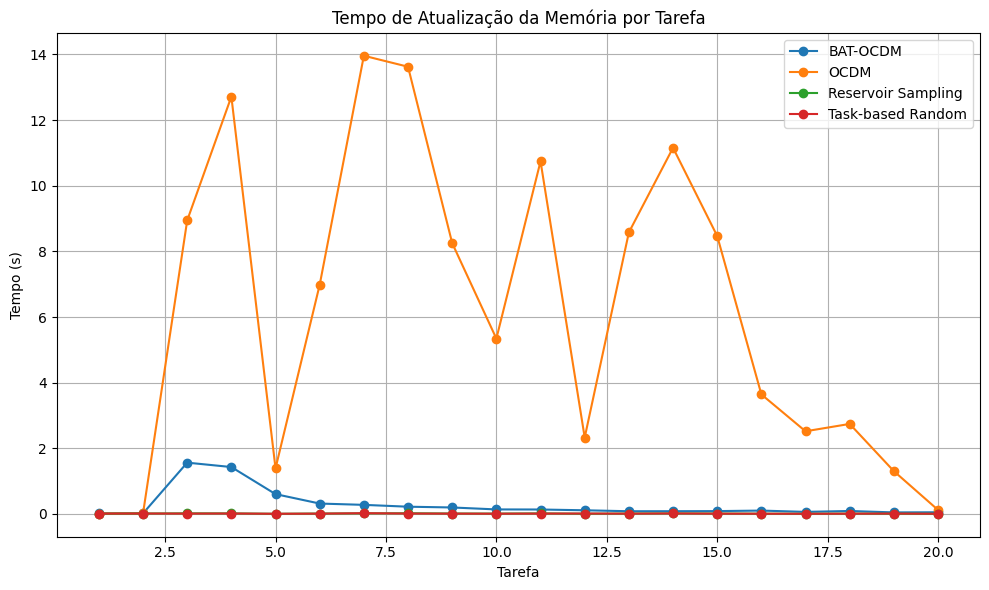

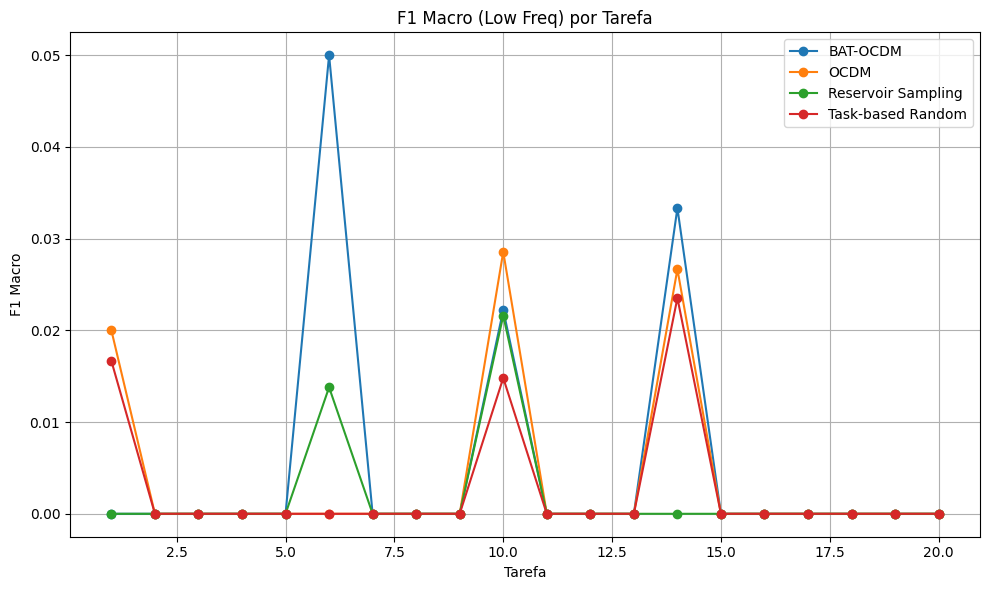

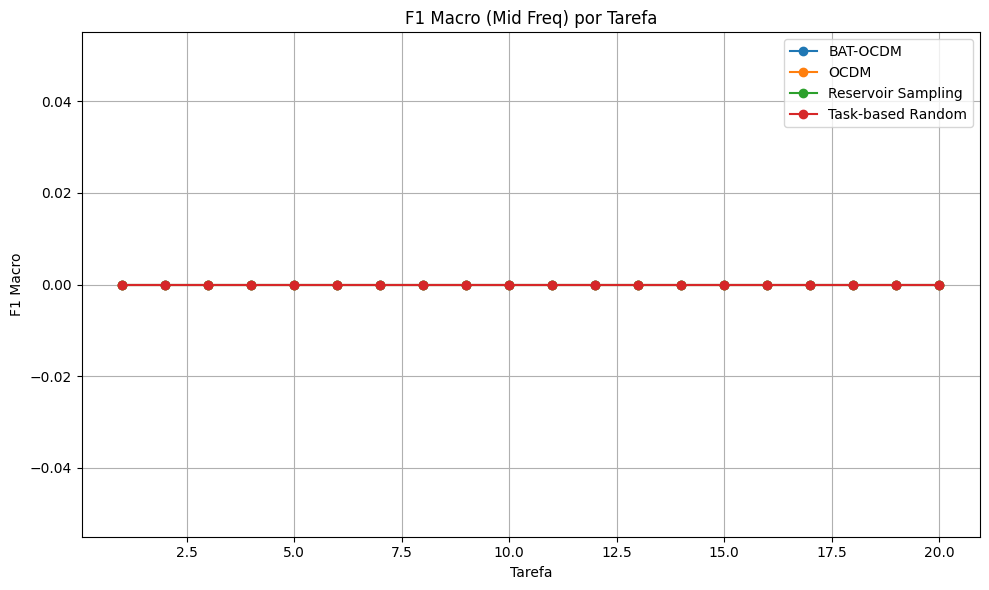

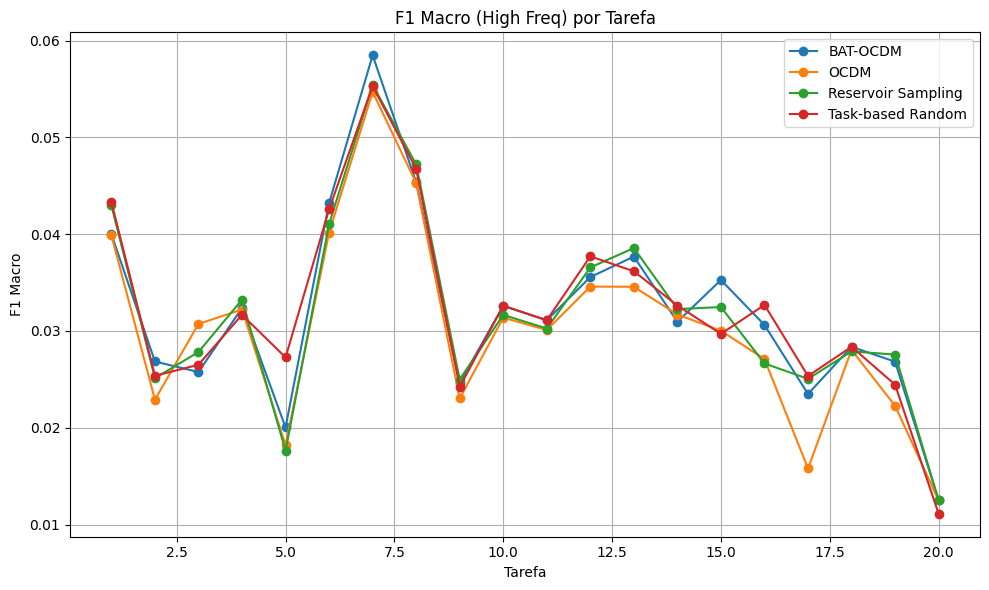

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict
# === Atualização: força num_workers=0 em before_training para evitar erro de multiprocessing no Windows ===
import types

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo = 0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        '''Reduced baseline model: feed-forward NN without sequential layers'''
        if alarm_num_out is None:
            alarm_num_out = alarm_num_in
        if 'hp_activation' in hparams.keys():
            activation = hparams['hp_activation']
        else:
            warnings.warn('Warning! Using default value for activation: tanh')
            activation = 'tanh'
        if hparams is not None and 'hp_dropout_rate' in hparams.keys():
            dropout_rate = hparams['hp_dropout_rate']
        else:
            warnings.warn('Warning! Using default value for dropout_rate : 0.5')
            dropout_rate = 0.5

        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
                        nn.Linear(alarm_num_in, 512),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(512, 256),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(256, 128),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(128, alarm_num_out),
                        nn.Sigmoid())


        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        output = self.net(X)
        return torch.squeeze(output, 1)

    def train_step(self, batch_data, memory_batch_size):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)


        # Forward step

        #y_pred = self.net(sample)
        y_pred = torch.squeeze(self.net(sample), 1)
        # Loss estimation
        loss = self.criterion(y_pred, y_true)
        loss = torch.mean(loss)
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)

        # Backward step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.detach().cpu().numpy()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = int(batch_size * (1 - self.rateo))

        #if len(self.plugin.x_memory) == 0:
        #    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
        #else:
        #    train_dataloader = DataLoader(train_dataset, batch_size=new_data_batch_size, shuffle=True, num_workers=0)
        times = {}
        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        end = time.time()
        times["before_training_time"] = abs(end - start)

        history = {}
        start = time.time()
        for epoch in range(epochs):
            print(f"EPOCH: {epoch + 1}/{epochs}")
            epoch_start = time.time()

            # Training step
            self.net.train()
            prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
            loss_epoch = []
            for _, batch_data in prog_bar:
                loss = self.train_step(batch_data, old_data_batch_size)
                loss_epoch.append(loss)
            loss_epoch = np.mean(loss_epoch)
            if 'loss' not in history.keys():
                history['loss'] = []
            history['loss'].append(loss_epoch)

            epoch_end = time.time()


            print(f"Time: {print_time_taken(epoch_start, epoch_end)} | loss: {loss_epoch:.4f}\n")


        end = time.time()
        times["train_time"] = abs(end - start)
        print(f"Training time: {print_time_taken(start, end)}")

        start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        end = time.time()
        times["add_data_to_memory_time"] = abs(end - start)

        return history, times

    def summary(self):
        summary(self.net, (self.alarm_num_in,))

class BasePlugin:
    def __init__(self, mem_size, device):
        super().__init__()
        self.mem_size = mem_size
        self.device = device

        self.x_memory = []  # <- Corrigido
        self.y_memory = []  # <- Corrigido
        self.x_tasks_memory = []
        self.y_tasks_memory = []

    def before_training(self, dataset):
        return DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)



class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0
        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho = 0
        self.target_count = None
        self.target_distribution = None

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = torch.randint(0, len(self.x_memory), (memory_batch_size,), device=self.device)
            x_mem_tensor = torch.tensor(np.array(self.x_memory), device=self.device)
            y_mem_tensor = torch.tensor(np.array(self.y_memory), device=self.device)
            return x_mem_tensor[indices], y_mem_tensor[indices]
        else:
            return None, None


    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_mem, y_mem = self._get_sample_from_memory(memory_batch_size)
        x_batch = batch_data[0].to(self.device)
        y_batch = batch_data[1].to(self.device).float()
        if x_mem is not None:
            x_batch = torch.cat((x_batch, x_mem), dim=0)
            y_batch = torch.cat((y_batch, y_mem.float()), dim=0)
        perm = torch.randperm(x_batch.size(0))
        return x_batch[perm], y_batch[perm]

    def update_target_distribution(self, y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = torch.zeros(num_labels, device=self.device)
            self.dataset_count = torch.zeros(num_labels, device=self.device)
            self.target_distribution = torch.zeros(num_labels, device=self.device)
        self.dataset_count += y_batch.sum(dim=0)
        self.num_samples_seen += y_batch.size(0)
        self.num_labels_seen += y_batch.sum()
        self.target_distribution = (self.dataset_count ** self.rho) / (self.num_labels_seen + 1e-8)
        self.target_count = self.target_distribution * self.num_samples_seen

class OCDM_Plugin(RehearsalPlugin):
    def add_data_to_memory(self, train_dataloader, dist_fn):
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            self.update_target_distribution(y_batch)
            memory_update(self.target_distribution.cpu().numpy(), x_batch.cpu().numpy(), y_batch.cpu().numpy(), self.x_memory, self.y_memory, dist_fn, self.mem_size, self.tasks_in_mem, self.task_number)
        self.task_number += 1

class BAT_OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)
        all_x = []
        all_y = []

        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            all_x.append(x_batch)
            all_y.append(y_batch)

        x_all = torch.cat(all_x)
        y_all = torch.cat(all_y)

        self.update_target_distribution(y_all)
        x_list = []
        y_list = []
        memory_update(self.target_distribution.cpu().numpy(), x_all.cpu().numpy(), y_all.cpu().numpy(), x_list, y_list, dist_fn, mem_size)
        self.x_tasks_memory.append(torch.tensor(np.array(x_list), device=self.device))
        self.y_tasks_memory.append(torch.tensor(np.array(y_list), device=self.device))

        # Resize anteriores
        for i in range(len(self.x_tasks_memory)):
            x_i, y_i = rehearsal_memory_resize(self.target_distribution.cpu().numpy(), self.x_tasks_memory[i].cpu().numpy(), self.y_tasks_memory[i].cpu().numpy(), dist_fn, mem_size)
            self.x_tasks_memory[i] = torch.tensor(x_i, device=self.device)
            self.y_tasks_memory[i] = torch.tensor(y_i, device=self.device)

        self.x_memory = torch.cat(self.x_tasks_memory, dim=0)
        self.y_memory = torch.cat(self.y_tasks_memory, dim=0)

class ReservoirSampling_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.total_samples_seen = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            for i in range(x_batch.size(0)):
                x_sample = x_batch[i].cpu().numpy()  # Converta para numpy
                y_sample = y_batch[i].cpu().numpy()  # Converta para numpy
                self.total_samples_seen += 1

                if len(self.x_memory) < self.mem_size:
                    # Use append() em vez de torch.cat()
                    self.x_memory.append(x_sample)
                    self.y_memory.append(y_sample)
                    self.tasks_in_mem.append(self.num_tasks)
                else:
                    j = random.randint(0, self.total_samples_seen - 1)
                    if j < self.mem_size:
                        # Substitua diretamente na lista
                        self.x_memory[j] = x_sample
                        self.y_memory[j] = y_sample
                        self.tasks_in_mem[j] = self.num_tasks

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = torch.randint(0, len(self.x_memory), (memory_batch_size,), device=self.device)
            # Converta explicitamente para tensor
            x_selected = torch.tensor(
                np.array([self.x_memory[i] for i in indices.cpu().numpy()]),
                device=self.device
            )
            y_selected = torch.tensor(
                np.array([self.y_memory[i] for i in indices.cpu().numpy()]),
                device=self.device
            )
            return x_selected, y_selected
        else:
            return None, None



# Same as MultiTaskSingleDynamicMemoryPlugin but keeping a proportional memory size based on the number of samples of a task
class task_based_random_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            sample_indexes = np.random.randint(len(self.x_tasks_memory[task]), size = mem_size, dtype=int)
            new_x_memory = self.x_tasks_memory[task][sample_indexes]
            new_y_memory = self.y_tasks_memory[task][sample_indexes]

            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        x_task_data_full = []
        y_task_data_full = []

        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])

        sample_indexes = np.random.randint(len(x_task_data_full), size = mem_size, dtype=int)
        self.x_tasks_memory[-1] = np.array(x_task_data_full)[sample_indexes]
        self.y_tasks_memory[-1] = np.array(y_task_data_full)[sample_indexes]
        del x_task_data_full
        del y_task_data_full

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


def cast_labels(y_true, y_pred):
    return y_true.type(torch.float32), y_pred.type(torch.float32) + EPS

def get_WFL(alpha, gamma):
    """
    Returns the Weighted Focal Loss (WFL)
    Args:
        alpha: weight parameter to compensate class imbalance.
        gamma: defines the rate at which easy examples are down-weighted:
               the higher ,the wider the range in which an example receives low loss.
    Example:
        alpha = 0.8
        gamma = 2.0
        loss_function = get_WFL(alpha, gamma)
    """
    def WFL(y_pred, y_true):
        if len(y_pred.shape) != len(y_true.shape):
            raise ValueError(f"Shape of y_pred {y_pred.shape} is different than y_true shape {y_true.shape}")
        y_real, y_pred = cast_labels(y_true, y_pred)
        loss = -alpha * torch.pow(1 - y_pred, gamma) * \
            y_true * torch.log(y_pred) - \
            (1 - alpha) * torch.pow(1 - (1 - y_pred), gamma) * \
            (1 - y_true) * torch.log(1 - y_pred)
        loss = torch.mean(loss.type(torch.float32))
        return loss
    return WFL

def labels_count(data_sample):
    count_alarms = np.zeros(data_sample.shape[1], dtype=int)  # Agora dinâmico
    for seq in data_sample:
        count_alarms[np.where(seq == 1)] += 1
    return count_alarms



def label_distribution(data_sample, rho = 1):
    count_alarms = labels_count(data_sample)
    count_alarms = count_alarms ** rho
    denom_sum = np.sum(count_alarms)
    return count_alarms / denom_sum


# === Funções otimizadas do rehearsal_utils ===

def min_index(target_distribution, data, dist_fn):
    min_dist = float("inf")
    min_idx = -1
    total_labels = data.sum(dim=0)
    for j in range(data.size(0)):
        candidate = total_labels - data[j]
        prob_distribution = candidate / (candidate.sum() + 1e-8)
        dist = dist_fn(prob_distribution.cpu().numpy(), target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_idx = j
    return min_idx

def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size=500, tasks_in_mem=None, task_number=None):
    x_batch = torch.tensor(x_batch) if isinstance(x_batch, np.ndarray) else x_batch
    y_batch = torch.tensor(y_batch) if isinstance(y_batch, np.ndarray) else y_batch
    batch_size = y_batch.size(0)
    remaining_size = mem_size - len(x_memory)

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        indices = torch.randperm(batch_size)[:size_sample]
        for i in indices:
            x_memory.append(x_batch[i].cpu().numpy())
            y_memory.append(y_batch[i].cpu().numpy())
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
    else:
        x_omega = torch.cat([torch.tensor(np.array(x_memory)), x_batch.cpu()])
        y_omega = torch.cat([torch.tensor(np.array(y_memory)), y_batch.cpu()])

        for _ in range(batch_size):
            idx = min_index(target_distribution, y_omega, dist_fn)
            x_omega = torch.cat([x_omega[:idx], x_omega[idx+1:]], dim=0)
            y_omega = torch.cat([y_omega[:idx], y_omega[idx+1:]], dim=0)
            if tasks_in_mem is not None and idx < mem_size:
                tasks_in_mem[idx] = task_number

        for i in range(mem_size):
            x_memory[i] = x_omega[i].numpy()
            y_memory[i] = y_omega[i].numpy()

def rehearsal_memory_resize(target_distribution, x_memory, y_memory, dist_fn, new_mem_size=500):
    x_tensor = torch.tensor(np.array(x_memory))
    y_tensor = torch.tensor(np.array(y_memory))
    items_to_remove = x_tensor.size(0) - new_mem_size
    for _ in range(items_to_remove):
        idx = min_index(target_distribution, y_tensor, dist_fn)
        x_tensor = torch.cat([x_tensor[:idx], x_tensor[idx+1:]], dim=0)
        y_tensor = torch.cat([y_tensor[:idx], y_tensor[idx+1:]], dim=0)
    return x_tensor.numpy(), y_tensor.numpy()

def get_activation(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'sigmoid':
        return nn.Sigmoid()
    else:
        raise ValueError(f"Unknown activation function: {name}")

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    # Verifica se tem memória para plotar
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    # Junta todos os tensores
    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

# Função para carregar dados reais do alarms.csv
def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    import pandas as pd
    from datetime import timedelta

    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas), dtype=torch.float32)
            y_task = torch.tensor(np.array(saidas), dtype=torch.float32)
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

def evaluate_model(model, dataset, device):
    from sklearn.metrics import accuracy_score, f1_score

    model.eval()
    all_preds = []
    all_labels = []
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro


def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1 / len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict
# === Atualização: força num_workers=0 em before_training para evitar erro de multiprocessing no Windows ===
import types

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo = 0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        '''Reduced baseline model: feed-forward NN without sequential layers'''
        if alarm_num_out is None:
            alarm_num_out = alarm_num_in
        if hparams is not None and 'hp_activation' in hparams.keys():
            activation = hparams['hp_activation']
        else:
            warnings.warn('Warning! Using default value for activation: tanh')
            activation = 'tanh'
        if hparams is not None and 'hp_dropout_rate' in hparams.keys():
            dropout_rate = hparams['hp_dropout_rate']
        else:
            warnings.warn('Warning! Using default value for dropout_rate : 0.5')
            dropout_rate = 0.5

        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
                        nn.Linear(alarm_num_in, 512),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(512, 256),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(256, 128),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(128, alarm_num_out),
                        nn.Sigmoid())


        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        output = self.net(X)
        return torch.squeeze(output, 1)

    def train_step(self, batch_data, memory_batch_size):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)


        # Forward step

        #y_pred = self.net(sample)
        y_pred = torch.squeeze(self.net(sample), 1)
        # Loss estimation
        loss = self.criterion(y_pred, y_true)
        loss = torch.mean(loss)
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)

        # Backward step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.detach().cpu().numpy()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = int(batch_size * (1 - self.rateo))

        #if len(self.plugin.x_memory) == 0:
        #    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
        #else:
        #    train_dataloader = DataLoader(train_dataset, batch_size=new_data_batch_size, shuffle=True, num_workers=0)
        times = {}
        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        end = time.time()
        times["before_training_time"] = abs(end - start)

        history = {}
        start = time.time()
        for epoch in range(epochs):
            print(f"EPOCH: {epoch + 1}/{epochs}")
            epoch_start = time.time()

            # Training step
            self.net.train()
            prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
            loss_epoch = []
            for _, batch_data in prog_bar:
                loss = self.train_step(batch_data, old_data_batch_size)
                loss_epoch.append(loss)
            loss_epoch = np.mean(loss_epoch)
            if 'loss' not in history.keys():
                history['loss'] = []
            history['loss'].append(loss_epoch)

            epoch_end = time.time()


            print(f"Time: {print_time_taken(epoch_start, epoch_end)} | loss: {loss_epoch:.4f}\n")


        end = time.time()
        times["train_time"] = abs(end - start)
        print(f"Training time: {print_time_taken(start, end)}")

        start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        end = time.time()
        times["add_data_to_memory_time"] = abs(end - start)

        return history, times

    def summary(self):
        summary(self.net, (self.alarm_num_in,))

class BasePlugin:
    def __init__(self, mem_size, device):
        super().__init__()
        self.mem_size = mem_size
        self.device = device

        self.x_memory = []  # <- Corrigido
        self.y_memory = []  # <- Corrigido
        self.x_tasks_memory = []
        self.y_tasks_memory = []

    def before_training(self, dataset):
        return DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)



class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0
        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho = 0
        self.target_count = None
        self.target_distribution = None

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = torch.randint(0, len(self.x_memory), (memory_batch_size,), device=self.device)
            x_mem_tensor = torch.tensor(np.array(self.x_memory), device=self.device)
            y_mem_tensor = torch.tensor(np.array(self.y_memory), device=self.device)
            return x_mem_tensor[indices], y_mem_tensor[indices]
        else:
            return None, None


    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_mem, y_mem = self._get_sample_from_memory(memory_batch_size)
        x_batch = batch_data[0].to(self.device)
        y_batch = batch_data[1].to(self.device).float()
        if x_mem is not None:
            x_batch = torch.cat((x_batch, x_mem), dim=0)
            y_batch = torch.cat((y_batch, y_mem.float()), dim=0)
        perm = torch.randperm(x_batch.size(0))
        return x_batch[perm], y_batch[perm]

    def update_target_distribution(self, y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = torch.zeros(num_labels, device=self.device)
            self.dataset_count = torch.zeros(num_labels, device=self.device)
            self.target_distribution = torch.zeros(num_labels, device=self.device)
        self.dataset_count += y_batch.sum(dim=0)
        self.num_samples_seen += y_batch.size(0)
        self.num_labels_seen += y_batch.sum()
        self.target_distribution = (self.dataset_count ** self.rho) / (self.num_labels_seen + 1e-8)
        self.target_count = self.target_distribution * self.num_samples_seen

class OCDM_Plugin(RehearsalPlugin):
    def add_data_to_memory(self, train_dataloader, dist_fn):
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            self.update_target_distribution(y_batch)
            memory_update(self.target_distribution.cpu().numpy(), x_batch.cpu().numpy(), y_batch.cpu().numpy(), self.x_memory, self.y_memory, dist_fn, self.mem_size, self.tasks_in_mem, self.task_number)
        self.task_number += 1

class BAT_OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)
        all_x = []
        all_y = []

        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            all_x.append(x_batch)
            all_y.append(y_batch)

        x_all = torch.cat(all_x)
        y_all = torch.cat(all_y)

        self.update_target_distribution(y_all)
        x_list = []
        y_list = []
        memory_update(self.target_distribution.cpu().numpy(), x_all.cpu().numpy(), y_all.cpu().numpy(), x_list, y_list, dist_fn, mem_size)
        self.x_tasks_memory.append(torch.tensor(np.array(x_list), device=self.device))
        self.y_tasks_memory.append(torch.tensor(np.array(y_list), device=self.device))

        # Resize anteriores
        for i in range(len(self.x_tasks_memory)):
            x_i, y_i = rehearsal_memory_resize(self.target_distribution.cpu().numpy(), self.x_tasks_memory[i].cpu().numpy(), self.y_tasks_memory[i].cpu().numpy(), dist_fn, mem_size)
            self.x_tasks_memory[i] = torch.tensor(x_i, device=self.device)
            self.y_tasks_memory[i] = torch.tensor(y_i, device=self.device)

        self.x_memory = torch.cat(self.x_tasks_memory, dim=0)
        self.y_memory = torch.cat(self.y_tasks_memory, dim=0)

class ReservoirSampling_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.total_samples_seen = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            for i in range(x_batch.size(0)):
                x_sample = x_batch[i].cpu().numpy()  # Converta para numpy
                y_sample = y_batch[i].cpu().numpy()  # Converta para numpy
                self.total_samples_seen += 1

                if len(self.x_memory) < self.mem_size:
                    # Use append() em vez de torch.cat()
                    self.x_memory.append(x_sample)
                    self.y_memory.append(y_sample)
                    self.tasks_in_mem.append(self.num_tasks)
                else:
                    j = random.randint(0, self.total_samples_seen - 1)
                    if j < self.mem_size:
                        # Substitua diretamente na lista
                        self.x_memory[j] = x_sample
                        self.y_memory[j] = y_sample
                        self.tasks_in_mem[j] = self.num_tasks

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = torch.randint(0, len(self.x_memory), (memory_batch_size,), device=self.device)
            # Converta explicitamente para tensor
            x_selected = torch.tensor(
                np.array([self.x_memory[i] for i in indices.cpu().numpy()]),
                device=self.device
            )
            y_selected = torch.tensor(
                np.array([self.y_memory[i] for i in indices.cpu().numpy()]),
                device=self.device
            )
            return x_selected, y_selected
        else:
            return None, None



# Same as MultiTaskSingleDynamicMemoryPlugin but keeping a proportional memory size based on the number of samples of a task
class task_based_random_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            sample_indexes = np.random.randint(len(self.x_tasks_memory[task]), size = mem_size, dtype=int)
            new_x_memory = self.x_tasks_memory[task][sample_indexes]
            new_y_memory = self.y_tasks_memory[task][sample_indexes]

            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        x_task_data_full = []
        y_task_data_full = []

        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])

        sample_indexes = np.random.randint(len(x_task_data_full), size = mem_size, dtype=int)
        self.x_tasks_memory[-1] = np.array(x_task_data_full)[sample_indexes]
        self.y_tasks_memory[-1] = np.array(y_task_data_full)[sample_indexes]
        del x_task_data_full
        del y_task_data_full

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


def cast_labels(y_true, y_pred):
    return y_true.type(torch.float32), y_pred.type(torch.float32) + EPS

def get_WFL(alpha, gamma):
    """
    Returns the Weighted Focal Loss (WFL)
    Args:
        alpha: weight parameter to compensate class imbalance.
        gamma: defines the rate at which easy examples are down-weighted:
               the higher ,the wider the range in which an example receives low loss.
    Example:
        alpha = 0.8
        gamma = 2.0
        loss_function = get_WFL(alpha, gamma)
    """
    def WFL(y_pred, y_true):
        if len(y_pred.shape) != len(y_true.shape):
            raise ValueError(f"Shape of y_pred {y_pred.shape} is different than y_true shape {y_true.shape}")
        y_real, y_pred = cast_labels(y_true, y_pred)
        loss = -alpha * torch.pow(1 - y_pred, gamma) * \
            y_true * torch.log(y_pred) - \
            (1 - alpha) * torch.pow(1 - (1 - y_pred), gamma) * \
            (1 - y_true) * torch.log(1 - y_pred)
        loss = torch.mean(loss.type(torch.float32))
        return loss
    return WFL

def labels_count(data_sample):
    count_alarms = np.zeros(data_sample.shape[1], dtype=int)  # Agora dinâmico
    for seq in data_sample:
        count_alarms[np.where(seq == 1)] += 1
    return count_alarms



def label_distribution(data_sample, rho = 1):
    count_alarms = labels_count(data_sample)
    count_alarms = count_alarms ** rho
    denom_sum = np.sum(count_alarms)
    return count_alarms / denom_sum


# === Funções otimizadas do rehearsal_utils ===

def min_index(target_distribution, data, dist_fn):
    min_dist = float("inf")
    min_idx = -1
    total_labels = data.sum(dim=0)
    for j in range(data.size(0)):
        candidate = total_labels - data[j]
        prob_distribution = candidate / (candidate.sum() + 1e-8)
        dist = dist_fn(prob_distribution.cpu().numpy(), target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_idx = j
    return min_idx

def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size=500, tasks_in_mem=None, task_number=None):
    x_batch = torch.tensor(x_batch) if isinstance(x_batch, np.ndarray) else x_batch
    y_batch = torch.tensor(y_batch) if isinstance(y_batch, np.ndarray) else y_batch
    batch_size = y_batch.size(0)
    remaining_size = mem_size - len(x_memory)

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        indices = torch.randperm(batch_size)[:size_sample]
        for i in indices:
            x_memory.append(x_batch[i].cpu().numpy())
            y_memory.append(y_batch[i].cpu().numpy())
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
    else:
        x_omega = torch.cat([torch.tensor(np.array(x_memory)), x_batch.cpu()])
        y_omega = torch.cat([torch.tensor(np.array(y_memory)), y_batch.cpu()])

        for _ in range(batch_size):
            idx = min_index(target_distribution, y_omega, dist_fn)
            x_omega = torch.cat([x_omega[:idx], x_omega[idx+1:]], dim=0)
            y_omega = torch.cat([y_omega[:idx], y_omega[idx+1:]], dim=0)
            if tasks_in_mem is not None and idx < mem_size:
                tasks_in_mem[idx] = task_number

        for i in range(mem_size):
            x_memory[i] = x_omega[i].numpy()
            y_memory[i] = y_omega[i].numpy()

def rehearsal_memory_resize(target_distribution, x_memory, y_memory, dist_fn, new_mem_size=500):
    x_tensor = torch.tensor(np.array(x_memory))
    y_tensor = torch.tensor(np.array(y_memory))
    items_to_remove = x_tensor.size(0) - new_mem_size
    for _ in range(items_to_remove):
        idx = min_index(target_distribution, y_tensor, dist_fn)
        x_tensor = torch.cat([x_tensor[:idx], x_tensor[idx+1:]], dim=0)
        y_tensor = torch.cat([y_tensor[:idx], y_tensor[idx+1:]], dim=0)
    return x_tensor.numpy(), y_tensor.numpy()

def get_activation(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'sigmoid':
        return nn.Sigmoid()
    else:
        raise ValueError(f"Unknown activation function: {name}")

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    # Verifica se tem memória para plotar
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    # Junta todos os tensores
    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

# Função para carregar dados reais do alarms.csv
def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    import pandas as pd
    from datetime import timedelta

    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas), dtype=torch.float32)
            y_task = torch.tensor(np.array(saidas), dtype=torch.float32)
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

def evaluate_model(model, dataset, device):
    from sklearn.metrics import accuracy_score, f1_score

    model.eval()
    all_preds = []
    all_labels = []
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro


def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1 / len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

# ====== EXECUÇÃO ======

# === Execução protegida para multiprocessing no Windows ===

if __name__ == "__main__":
    import torch.multiprocessing as mp
    mp.set_start_method("spawn", force=True)



    def safe_kl(p, q):
        p = np.asarray(p, dtype=np.float32) + 1e-8
        q = np.asarray(q, dtype=np.float32) + 1e-8
        p /= p.sum()
        q /= q.sum()
        return np.sum(np.where(p != 0, p * np.log(p / q), 0))

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
    mem_size = 400

    strategies = {
        "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
        "OCDM": OCDM_Plugin(mem_size, device),
        "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
        "Task-based Random": task_based_random_Plugin(mem_size, device)
    }

    all_times_per_strategy = {name: [] for name in strategies}
    all_f1_grouped_per_strategy = {name: {'Low': [], 'Mid': [], 'High': []} for name in strategies}

    for strategy_name, plugin in strategies.items():
        print(f"\n=== Estratégia {strategy_name} ===")
        model = ASC_BR_Multilabel_Rehearsal(None, input_dim, plugin, hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}).to(device)

        for i, task in enumerate(tasks):
            print(f"\n-- Tarefa {i+1} --")
            history, times = model.fit(epochs=5, train_dataset=task, batch_size=64, dist_fn=safe_kl, device=device)
            all_times_per_strategy[strategy_name].append(times)

            # Calcular métricas
            X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
            with torch.no_grad():
                outputs = model(X)
                preds = (outputs > 0.5).float().cpu().numpy()
                labels = Y.cpu().numpy()

            # Calcular F1 para diferentes grupos (substitua com sua lógica real)
            # ESTA É UMA IMPLEMENTAÇÃO DE EXEMPLO - ADAPTE PARA SEU CASO
            f1_low = f1_score(labels[:, :5], preds[:, :5], average='macro', zero_division=0)
            f1_mid = f1_score(labels[:, 5:10], preds[:, 5:10], average='macro', zero_division=0)
            f1_high = f1_score(labels[:, 10:], preds[:, 10:], average='macro', zero_division=0)

            # Armazenar métricas
            all_f1_grouped_per_strategy[strategy_name]['Low'].append(f1_low)
            all_f1_grouped_per_strategy[strategy_name]['Mid'].append(f1_mid)
            all_f1_grouped_per_strategy[strategy_name]['High'].append(f1_high)

    # ===== PLOTS =====
    task_numbers = list(range(1, len(tasks)+1))

    # Plot Parte 3: tempo de atualização da memória
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
        plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
    plt.title('Tempo de Atualização da Memória por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('Tempo (s)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot Parte 1: F1 por frequência
    for group in ['Low', 'Mid', 'High']:
        plt.figure(figsize=(10, 6))
        for strategy_name in strategies:
            plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
        plt.title(f'F1 Macro ({group} Freq) por Tarefa')
        plt.xlabel('Tarefa')
        plt.ylabel('F1 Macro')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --
EPOCH: 1/5


3it [00:00, 79.48it/s]               


Time: 0m 0s | loss: 0.0371

EPOCH: 2/5


3it [00:00, 77.23it/s]               


Time: 0m 0s | loss: 0.0305

EPOCH: 3/5


3it [00:00, 63.22it/s]               


... (954 outputs left out)

1it [00:00, 72.97it/s]


Time: 0m 0s | loss: 0.0067

Training time: 0m 0s


1it [00:00, 369.35it/s]


Number of memories 20
Mem 0 has lenght of 20
Mem 1 has lenght of 20
Mem 2 has lenght of 20
Mem 3 has lenght of 20
Mem 4 has lenght of 20
Mem 5 has lenght of 20
Mem 6 has lenght of 20
Mem 7 has lenght of 20
Mem 8 has lenght of 20
Mem 9 has lenght of 20
Mem 10 has lenght of 20
Mem 11 has lenght of 20
Mem 12 has lenght of 20
Mem 13 has lenght of 20
Mem 14 has lenght of 20
Mem 15 has lenght of 20
Mem 16 has lenght of 20
Mem 17 has lenght of 20
Mem 18 has lenght of 20
Mem 19 has lenght of 20
Total memory length is 400
F1 Macro (Low freq): 0.0000
F1 Macro (Mid freq): 0.0000
F1 Macro (High freq): 0.0571


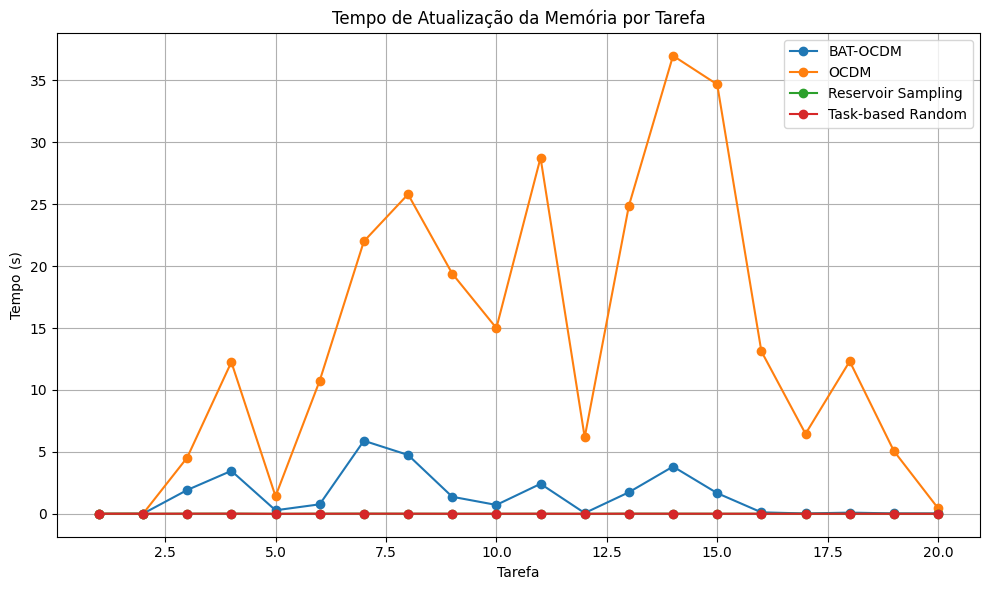

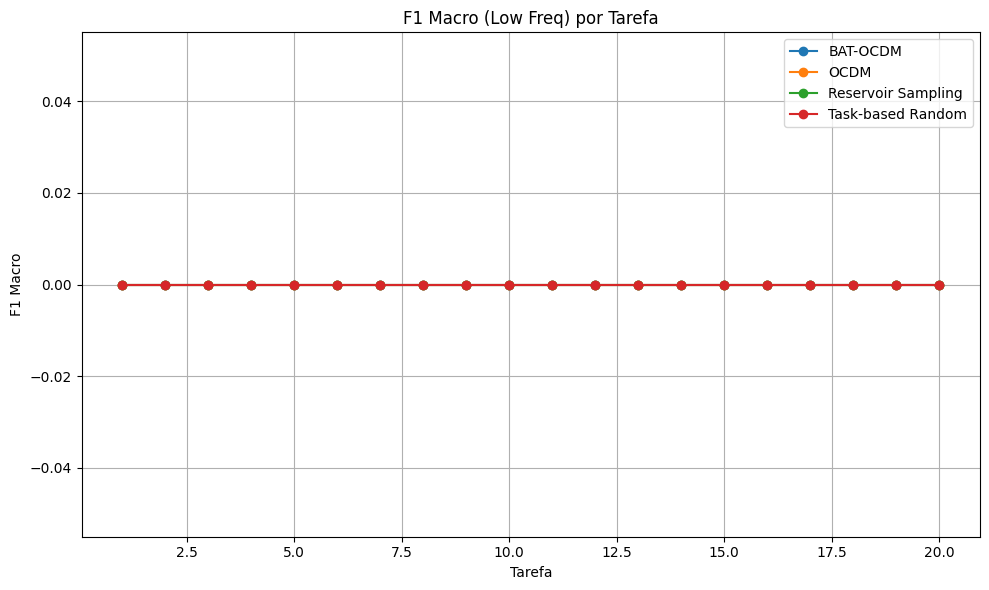

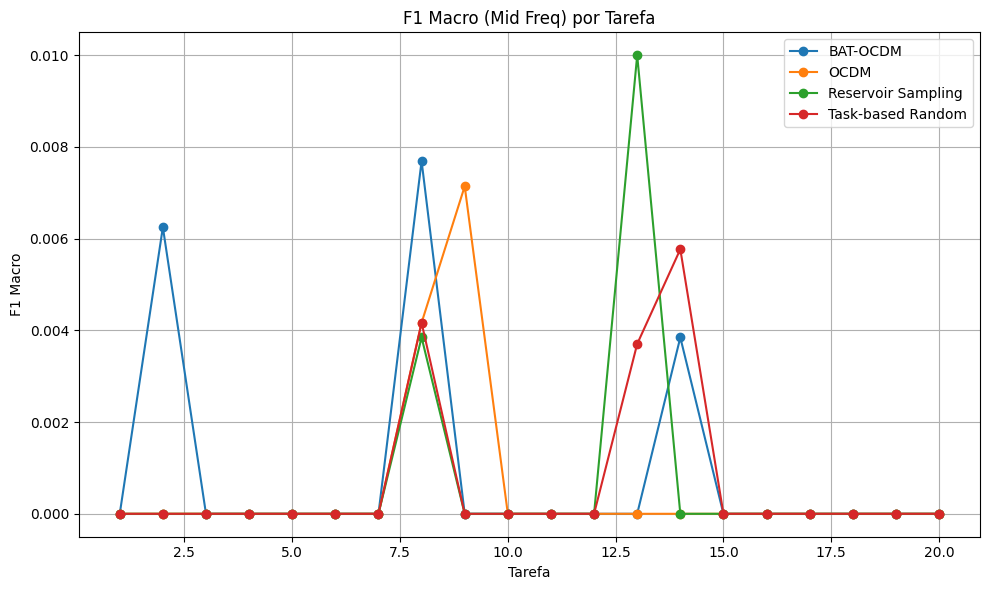

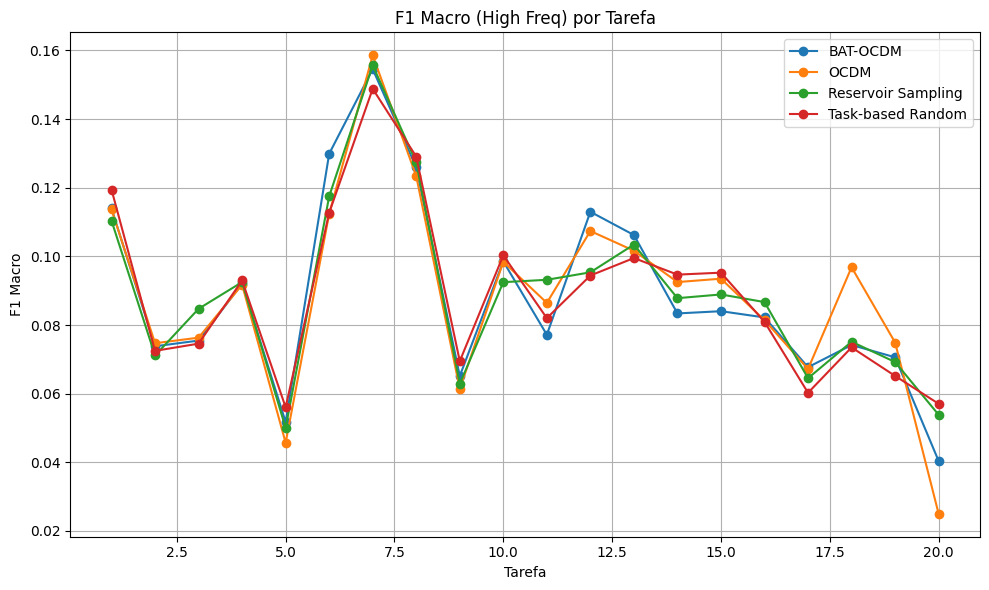

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo = 0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        '''Reduced baseline model: feed-forward NN without sequential layers'''
        if alarm_num_out is None:
            alarm_num_out = alarm_num_in
        if 'hp_activation' in hparams.keys():
            activation = hparams['hp_activation']
        else:
            warnings.warn('Warning! Using default value for activation: tanh')
            activation = 'tanh'
        if hparams is not None and 'hp_dropout_rate' in hparams.keys():
            dropout_rate = hparams['hp_dropout_rate']
        else:
            warnings.warn('Warning! Using default value for dropout_rate : 0.5')
            dropout_rate = 0.5

        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
                        nn.Linear(alarm_num_in, 512),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(512, 256),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(256, 128),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(128, alarm_num_out),
                        nn.Sigmoid())


        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        output = self.net(X)
        return torch.squeeze(output, 1)

    def train_step(self, batch_data, memory_batch_size):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)


        # Forward step

        #y_pred = self.net(sample)
        y_pred = torch.squeeze(self.net(sample), 1)
        # Loss estimation
        loss = self.criterion(y_pred, y_true)
        loss = torch.mean(loss)
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)

        # Backward step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.detach().cpu().numpy()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = int(batch_size * (1 - self.rateo))

        #if len(self.plugin.x_memory) == 0:
        #    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
        #else:
        #    train_dataloader = DataLoader(train_dataset, batch_size=new_data_batch_size, shuffle=True, num_workers=0)
        times = {}
        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        end = time.time()
        times["before_training_time"] = abs(end - start)

        history = {}
        start = time.time()
        for epoch in range(epochs):
            print(f"EPOCH: {epoch + 1}/{epochs}")
            epoch_start = time.time()

            # Training step
            self.net.train()
            prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
            loss_epoch = []
            for _, batch_data in prog_bar:
                loss = self.train_step(batch_data, old_data_batch_size)
                loss_epoch.append(loss)
            loss_epoch = np.mean(loss_epoch)
            if 'loss' not in history.keys():
                history['loss'] = []
            history['loss'].append(loss_epoch)

            epoch_end = time.time()


            print(f"Time: {print_time_taken(epoch_start, epoch_end)} | loss: {loss_epoch:.4f}\n")


        end = time.time()
        times["train_time"] = abs(end - start)
        print(f"Training time: {print_time_taken(start, end)}")

        start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        end = time.time()
        times["add_data_to_memory_time"] = abs(end - start)

        return history, times

    def summary(self):
        summary(self.net, (self.alarm_num_in,))

class BasePlugin:

    def __init__(self, mem_size, device):
        super().__init__()
        self.mem_size = mem_size
        self.x_tasks_memory = [] # It shold be a matrix
        self.y_tasks_memory = [] # It should be a matrix
        self.x_memory = []
        self.y_memory = []
        self.device = device

    def before_training(self, dataset):
        if len(self.x_memory) == 0:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        else:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        return train_dataloader


    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        return batch_data[0], batch_data[1]

    def add_data_to_memory(self, train_dataloader, dist_fn):
       # do nothing
       pass

    def get_tasks_in_memory(self):
        return []

class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0

        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho=0

        self.target_count = None
        self.dataset_count = None
        self.target_distribution = None


    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            sample_indexes = np.random.randint(len(self.x_memory), size = memory_batch_size, dtype=int)
            x_memory_selected = torch.from_numpy(np.array(self.x_memory)[sample_indexes]).to(self.device)
            y_memory_selected = torch.from_numpy(np.array(self.y_memory)[sample_indexes]).to(self.device)
        else:
            x_memory_selected = None
            y_memory_selected = None
        return x_memory_selected, y_memory_selected

    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_memory_sampled, y_memory_sampled = self._get_sample_from_memory(memory_batch_size)
        sample = batch_data[0] if x_memory_sampled is None else torch.cat((batch_data[0], x_memory_sampled), 0)
        y_true = batch_data[1].type(torch.float32) if y_memory_sampled is None else torch.cat((batch_data[1].type(torch.float32), y_memory_sampled.type(torch.float32)), 0)
        sample, y_true = sklearn.utils.shuffle(sample, y_true)
        return sample, y_true

    def update_target_distribution(self,y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = np.zeros(num_labels)
            self.dataset_count = np.zeros(num_labels)
            self.target_distribution = np.zeros(num_labels)


        self.dataset_count += y_batch.sum(axis=0)
        self.num_samples_seen+=y_batch.shape[0]
        self.num_labels_seen+=y_batch.sum()
        self.target_distribution = (self.dataset_count** self.rho)/self.num_labels_seen
        self.target_count = self.target_distribution*self.num_samples_seen



class OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device, rho=0):
        super().__init__(mem_size, device)
        self.rho = rho

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            # Fixed call with correct arguments
            memory_update(
                self.target_distribution,
                x_batch,
                y_batch,
                self.x_memory,
                self.y_memory,
                dist_fn,
                self.mem_size
            )
        self.task_number += 1

    def get_tasks_distribution_in_memory(self):
        values, counts = np.unique(self.tasks_in_mem, return_counts=True)
        tasks_count = np.zeros(14)
        for i in range(len(values)):
            tasks_count[values[i]] = counts[i]
        return tasks_count


# From a memory of mem_size, the new samples of a task are added to memory by resizing dinamycally the number of samples to keep in memory for each task.
class BAT_OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)

        self.x_tasks_memory.append([])
        self.y_tasks_memory.append([])
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            # Fixed call with correct arguments
            memory_update(
                self.target_distribution,
                x_batch,
                y_batch,
                self.x_tasks_memory[-1],
                self.y_tasks_memory[-1],
                dist_fn,
                mem_size
            )

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            new_x_memory, new_y_memory = rehearsal_memory_resize(
                self.target_distribution,
                self.x_tasks_memory[task],
                self.y_tasks_memory[task],
                dist_fn,
                mem_size
            )
            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            self.x_memory.extend(self.x_tasks_memory[task])
            self.y_memory.extend(self.y_tasks_memory[task])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has length of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_distribution_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


class ReservoirSampling_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.num_data = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        #num_data = len(train_dataloader.dataset)
        x_task_data_full = []
        y_task_data_full = []
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])
        prev_num_data = self.num_data
        self.num_data += len(x_task_data_full)
        for i in range(0, self.num_data):
            if i < prev_num_data:
                continue
            dataset_index = i - prev_num_data

            if len(self.x_memory) <= self.mem_size:

                self.x_memory.append(x_task_data_full[dataset_index])
                self.y_memory.append(y_task_data_full[dataset_index])
                self.tasks_in_mem.append(self.num_tasks)
            else:
                j = random.randint(0, i)
                if j < self.mem_size:
                    #print(f"dataset_size: {len(x_task_data_full)}   index: {dataset_index}    i: {i}  prev_num: {prev_num_data}  num_data: {self.num_data}")
                    self.x_memory[j] = x_task_data_full[dataset_index]
                    self.y_memory[j] = y_task_data_full[dataset_index]
                    self.tasks_in_mem[j] = self.num_tasks
        del x_task_data_full
        del y_task_data_full

        self.num_tasks += 1 # New task to add, the counter is incremented

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        unique, counts = np.unique(self.tasks_in_mem, return_counts=True)
        dict_counts = dict(zip(unique, counts))
        for key in dict_counts:
            tasks_count[key] = dict_counts[key]
        return tasks_count



# Same as MultiTaskSingleDynamicMemoryPlugin but keeping a proportional memory size based on the number of samples of a task
class task_based_random_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            sample_indexes = np.random.randint(len(self.x_tasks_memory[task]), size = mem_size, dtype=int)
            new_x_memory = self.x_tasks_memory[task][sample_indexes]
            new_y_memory = self.y_tasks_memory[task][sample_indexes]

            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        x_task_data_full = []
        y_task_data_full = []

        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])

        sample_indexes = np.random.randint(len(x_task_data_full), size = mem_size, dtype=int)
        self.x_tasks_memory[-1] = np.array(x_task_data_full)[sample_indexes]
        self.y_tasks_memory[-1] = np.array(y_task_data_full)[sample_indexes]
        del x_task_data_full
        del y_task_data_full

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count

def cast_labels(y_true, y_pred):
    return y_true.type(torch.float32), y_pred.type(torch.float32) + EPS

def get_WFL(alpha, gamma):
    """
    Returns the Weighted Focal Loss (WFL)
    Args:
        alpha: weight parameter to compensate class imbalance.
        gamma: defines the rate at which easy examples are down-weighted:
               the higher ,the wider the range in which an example receives low loss.
    Example:
        alpha = 0.8
        gamma = 2.0
        loss_function = get_WFL(alpha, gamma)
    """
    def WFL(y_pred, y_true):
        if len(y_pred.shape) != len(y_true.shape):
            raise ValueError(f"Shape of y_pred {y_pred.shape} is different than y_true shape {y_true.shape}")
        y_real, y_pred = cast_labels(y_true, y_pred)
        loss = -alpha * torch.pow(1 - y_pred, gamma) * \
            y_true * torch.log(y_pred) - \
            (1 - alpha) * torch.pow(1 - (1 - y_pred), gamma) * \
            (1 - y_true) * torch.log(1 - y_pred)
        loss = torch.mean(loss.type(torch.float32))
        return loss
    return WFL

def labels_count(data_sample):
    # Convert to numpy array if not already
    if not isinstance(data_sample, np.ndarray):
        data_sample = np.array(data_sample)

    # Handle empty arrays
    if data_sample.size == 0:
        return np.zeros(0, dtype=int)

    # Handle 1D arrays (single sample)
    if data_sample.ndim == 1:
        return data_sample.astype(int)

    # For 2D+ arrays, sum along the samples axis
    return data_sample.sum(axis=0).astype(int)



def label_distribution(data_sample, rho = 1):
    count_alarms = labels_count(data_sample)
    count_alarms = count_alarms ** rho
    denom_sum = np.sum(count_alarms)
    return count_alarms / denom_sum


def min_index(target_distribution,data, dist_fn):
    min_dist = float("inf")
    min_index = -1
    prob_counts = labels_count(data)
    for j in range(len(data)):
        new_counts = prob_counts - data[j]
        prob_distribution = new_counts / np.sum(new_counts)

        dist = dist_fn(prob_distribution, target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_index = j
    return min_index


# Applies the OCDM (Optimizing Class Distribution in Memory) algorithm from this paper: https://openreview.net/forum?id=HavXnq6KyT3
def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size=500, domain_labels=None):
    batch_size = len(y_batch)
    remaining_size = mem_size - len(x_memory)

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        sample_indexes = np.random.choice(len(y_batch), size=size_sample, replace=False)
        x_memory.extend(x_batch[sample_indexes])
        y_memory.extend(y_batch[sample_indexes])
        if domain_labels:
            domain_labels.extend(domain_labels[sample_indexes])
    else:
        # Convert to arrays for safe manipulation
        x_memory_arr = np.array(x_memory)
        y_memory_arr = np.array(y_memory)
        x_batch_arr = np.array(x_batch)
        y_batch_arr = np.array(y_batch)

        # Create combined arrays with vertical stacking
        x_omega = np.vstack((x_memory_arr, x_batch_arr))
        y_omega = np.vstack((y_memory_arr, y_batch_arr))

        # Compute class counts from combined data
        class_counts = labels_count(y_omega)

        # Handle domain labels if present
        domain_omega = None
        if domain_labels:
            domain_labels_arr = np.array(domain_labels)
            domain_omega = domain_labels_arr  # Simplified since batch domains aren't provided

        # Create mask for samples to keep
        mask = np.ones(len(y_omega), dtype=bool)
        for _ in range(batch_size):
            i = select_removal_index(target_distribution, y_omega, domain_omega, class_counts, None, dist_fn)
            mask[i] = False

        # Convert back to lists
        x_memory[:] = list(x_omega[mask])
        y_memory[:] = list(y_omega[mask])
        if domain_labels and domain_omega is not None:
            domain_labels[:] = list(domain_omega[mask])

def select_removal_index(target_distribution, y_data, domain_data, class_counts, domain_counts, dist_fn):
    """Seleciona o melhor exemplo para remoção considerando classe e domínio."""
    min_dist = float("inf")
    min_index = -1

    for j, sample in enumerate(y_data):
        # Avaliação da perda de diversidade ao remover este exemplo
        new_class_counts = np.clip(class_counts - sample, a_min=0, a_max=None)
        class_distribution = new_class_counts / np.sum(new_class_counts + 1e-6)

        if domain_data is not None:
            new_domain_counts = np.clip(domain_counts - domain_data[j], a_min=0, a_max=None)
            domain_distribution = new_domain_counts / np.sum(new_domain_counts + 1e-6)
            dist_class = dist_fn(class_distribution, target_distribution)
            dist_domain = dist_fn(domain_distribution, target_distribution)
            dist = dist_class + 0.5 * dist_domain  # Peso maior na classe, menor no domínio
        else:
            dist = dist_fn(class_distribution, target_distribution)

        if dist < min_dist:
            min_dist = dist
            min_index = j

    return min_index



def rehearsal_memory_resize(target_distribution,x_memory, y_memory, dist_fn, new_mem_size = 500):
    x_memory_np = np.array(x_memory)
    y_memory_np = np.array(y_memory)

    items_to_remove = len(x_memory) - new_mem_size
    for k in range(items_to_remove):
        i = min_index(target_distribution,y_memory_np, dist_fn)
        x_memory_np = np.delete(x_memory_np, i, axis=0)
        y_memory_np = np.delete(y_memory_np, i, axis=0)
    x_memory = []
    y_memory = []
    for i in range(len(x_memory_np)):
        x_memory.append(x_memory_np[i])
        y_memory.append(y_memory_np[i])
    return x_memory, y_memory


def get_activation(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'sigmoid':
        return nn.Sigmoid()
    else:
        raise ValueError(f"Unknown activation function: {name}")

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    # Verifica se tem memória para plotar
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    # Junta todos os tensores
    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

# Função para carregar dados reais do alarms.csv
def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    equipamentos = df['serial'].unique()  # serial = máquina
    alarmes_unicos = df['alarm'].unique()  # alarm = código do alarme

    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)

    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()

        entradas = []
        saidas = []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    input_dim = num_alarmes
    return tasks, input_dim


# Função para avaliar modelo
def evaluate_model(model, dataset, device):
    model.eval()
    all_preds = []
    all_labels = []
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro

def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1 / len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def carregar_dados_alarms_csv(caminho_alarms='./alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

# ====== EXECUÇÃO ======

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
mem_size = 400

strategies = {
    "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
    "OCDM": OCDM_Plugin(mem_size, device),
    "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
    "Task-based Random": task_based_random_Plugin(mem_size, device)
}

# Inicializa métricas
all_times_per_strategy = {}
all_f1_grouped_per_strategy = {}

# Frequência dos rótulos para dividir em grupos
all_outputs = torch.cat([t.tensors[1] for t in tasks], dim=0)
alarm_freq = all_outputs.sum(dim=0).numpy()
percentis = np.percentile(alarm_freq, [33.3, 66.6])
low, mid, high = [], [], []
for idx, count in enumerate(alarm_freq):
    if count <= percentis[0]: low.append(idx)
    elif count <= percentis[1]: mid.append(idx)
    else: high.append(idx)
freq_groups = {'Low': low, 'Mid': mid, 'High': high}

def f1_macro_grouped(y_true, y_pred, group_indices):
    f1s = f1_score(y_true[:, group_indices], y_pred[:, group_indices], average=None, zero_division=0)
    return np.mean(f1s)

for strategy_name, plugin in strategies.items():
    print(f"\n=== Estratégia {strategy_name} ===")
    model = ASC_BR_Multilabel_Rehearsal(None, input_dim, plugin, hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}).to(device)

    all_times = []
    f1_by_group = defaultdict(list)

    for i, task in enumerate(tasks):
        print(f"\n-- Tarefa {i+1} --")
        history, times = model.fit(epochs=5, train_dataset=task, batch_size=64, dist_fn=safe_kl, device=device)
        all_times.append(times)

        X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
        with torch.no_grad():
            preds = (model(X) > 0.5).float().cpu().numpy()
            labels = Y.cpu().numpy()

        for group, indices in freq_groups.items():
            score = f1_macro_grouped(labels, preds, indices)
            f1_by_group[group].append(score)
            print(f"F1 Macro ({group} freq): {score:.4f}")

    all_times_per_strategy[strategy_name] = all_times
    all_f1_grouped_per_strategy[strategy_name] = f1_by_group

# Plot resultados Parte 3: tempo de atualização da memória
plt.figure(figsize=(10, 6))
task_numbers = list(range(1, len(tasks)+1))
for strategy_name in strategies:
    memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
    plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
plt.title('Tempo de Atualização da Memória por Tarefa')
plt.xlabel('Tarefa')
plt.ylabel('Tempo (s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Parte 1: F1 por frequência
for group in ['Low', 'Mid', 'High']:
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
    plt.title(f'F1 Macro ({group} Freq) por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('F1 Macro')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --
EPOCH: 1/5


3it [00:00, 101.54it/s]              


Time: 0m 0s | loss: 0.0366

EPOCH: 2/5


3it [00:00, 88.89it/s]               


Time: 0m 0s | loss: 0.0300

EPOCH: 3/5


3it [00:00, 103.85it/s]              


... (955 outputs left out)

1it [00:00, 82.39it/s]


Time: 0m 0s | loss: 0.0061

Training time: 0m 0s


1it [00:00, 599.10it/s]


Number of memories 20
Mem 0 has lenght of 20
Mem 1 has lenght of 20
Mem 2 has lenght of 20
Mem 3 has lenght of 20
Mem 4 has lenght of 20
Mem 5 has lenght of 20
Mem 6 has lenght of 20
Mem 7 has lenght of 20
Mem 8 has lenght of 20
Mem 9 has lenght of 20
Mem 10 has lenght of 20
Mem 11 has lenght of 20
Mem 12 has lenght of 20
Mem 13 has lenght of 20
Mem 14 has lenght of 20
Mem 15 has lenght of 20
Mem 16 has lenght of 20
Mem 17 has lenght of 20
Mem 18 has lenght of 20
Mem 19 has lenght of 20
Total memory length is 400
F1 Macro (Low freq): 0.0000
F1 Macro (Mid freq): 0.0000
F1 Macro (High freq): 0.0346


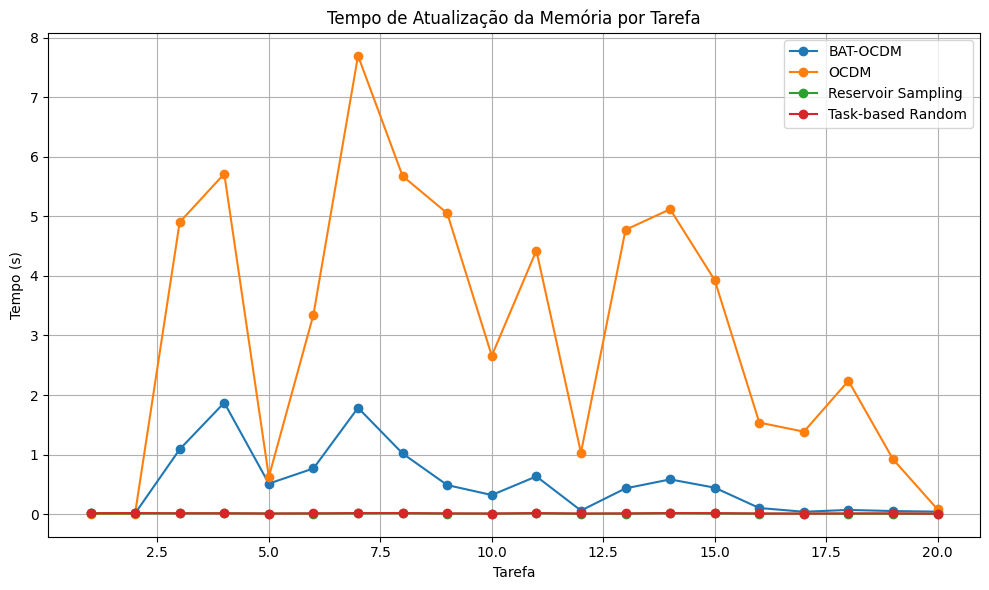

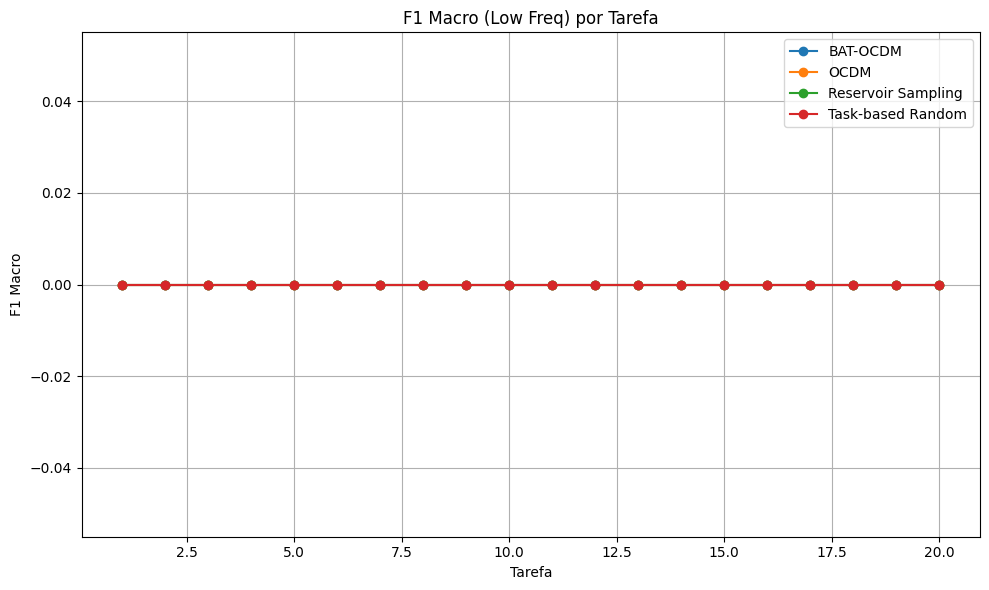

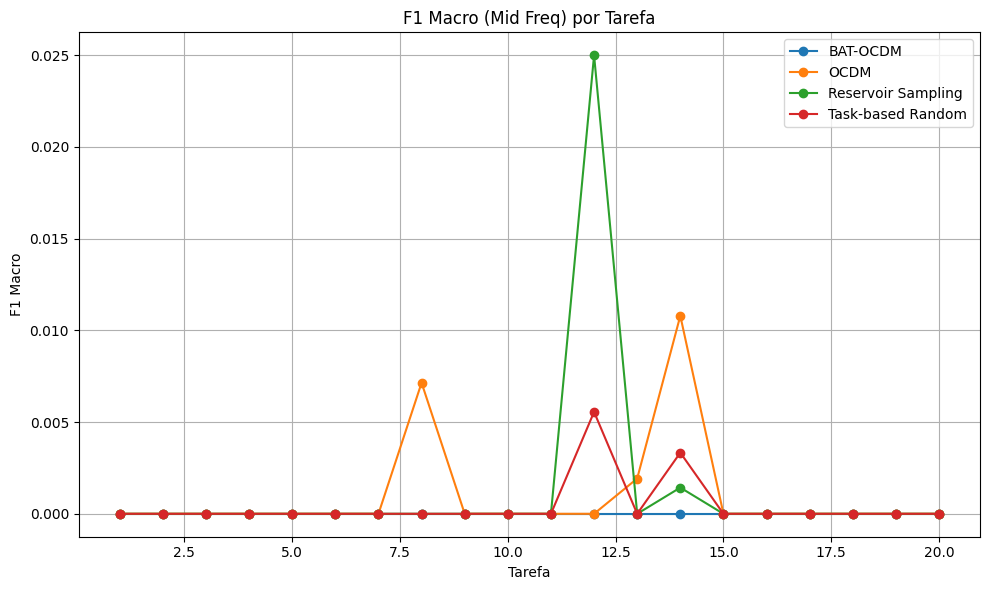

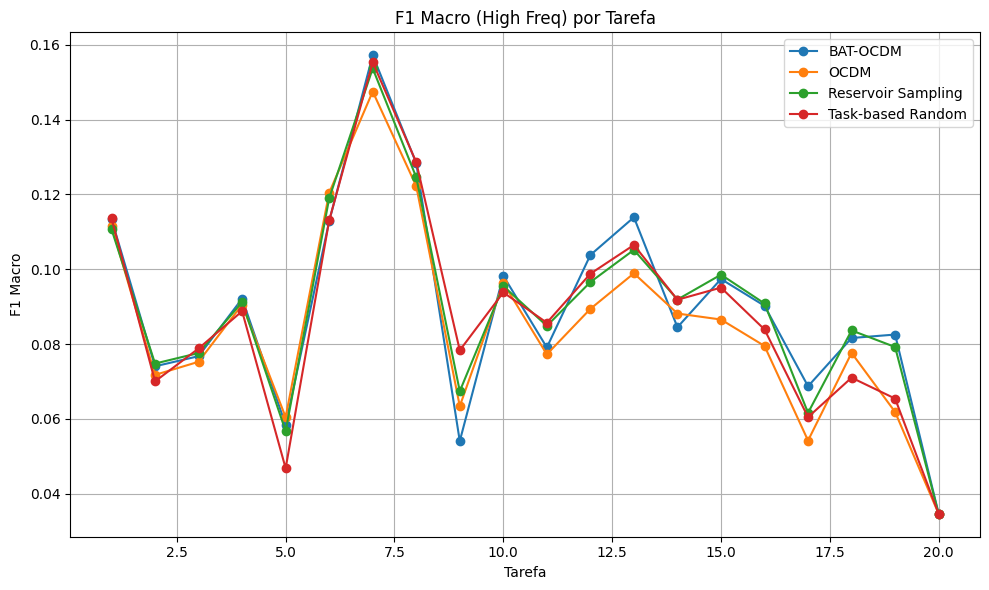

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo = 0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        '''Reduced baseline model: feed-forward NN without sequential layers'''
        if alarm_num_out is None:
            alarm_num_out = alarm_num_in
        if 'hp_activation' in hparams.keys():
            activation = hparams['hp_activation']
        else:
            warnings.warn('Warning! Using default value for activation: tanh')
            activation = 'tanh'
        if hparams is not None and 'hp_dropout_rate' in hparams.keys():
            dropout_rate = hparams['hp_dropout_rate']
        else:
            warnings.warn('Warning! Using default value for dropout_rate : 0.5')
            dropout_rate = 0.5

        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
                        nn.Linear(alarm_num_in, 512),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(512, 256),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(256, 128),
                        get_activation(activation),
                        nn.Dropout(dropout_rate),
                        nn.Linear(128, alarm_num_out),
                        nn.Sigmoid())


        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        output = self.net(X)
        return torch.squeeze(output, 1)

    def train_step(self, batch_data, memory_batch_size):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)


        # Forward step

        #y_pred = self.net(sample)
        y_pred = torch.squeeze(self.net(sample), 1)
        # Loss estimation
        loss = self.criterion(y_pred, y_true)
        loss = torch.mean(loss)
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)

        # Backward step
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.detach().cpu().numpy()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = int(batch_size * (1 - self.rateo))

        #if len(self.plugin.x_memory) == 0:
        #    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
        #else:
        #    train_dataloader = DataLoader(train_dataset, batch_size=new_data_batch_size, shuffle=True, num_workers=0)
        times = {}
        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        end = time.time()
        times["before_training_time"] = abs(end - start)

        history = {}
        start = time.time()
        for epoch in range(epochs):
            print(f"EPOCH: {epoch + 1}/{epochs}")
            epoch_start = time.time()

            # Training step
            self.net.train()
            prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
            loss_epoch = []
            for _, batch_data in prog_bar:
                loss = self.train_step(batch_data, old_data_batch_size)
                loss_epoch.append(loss)
            loss_epoch = np.mean(loss_epoch)
            if 'loss' not in history.keys():
                history['loss'] = []
            history['loss'].append(loss_epoch)

            epoch_end = time.time()


            print(f"Time: {print_time_taken(epoch_start, epoch_end)} | loss: {loss_epoch:.4f}\n")


        end = time.time()
        times["train_time"] = abs(end - start)
        print(f"Training time: {print_time_taken(start, end)}")

        start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        end = time.time()
        times["add_data_to_memory_time"] = abs(end - start)

        return history, times

    def summary(self):
        summary(self.net, (self.alarm_num_in,))

class BasePlugin:

    def __init__(self, mem_size, device):
        super().__init__()
        self.mem_size = mem_size
        self.x_tasks_memory = [] # It shold be a matrix
        self.y_tasks_memory = [] # It should be a matrix
        self.x_memory = []
        self.y_memory = []
        self.device = device

    def before_training(self, dataset):
        if len(self.x_memory) == 0:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        else:
            train_dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)
        return train_dataloader


    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        return batch_data[0], batch_data[1]

    def add_data_to_memory(self, train_dataloader, dist_fn):
       # do nothing
       pass

    def get_tasks_in_memory(self):
        return []

class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0

        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho=0

        self.target_count = None
        self.dataset_count = None
        self.target_distribution = None


    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            sample_indexes = np.random.randint(len(self.x_memory), size = memory_batch_size, dtype=int)
            x_memory_selected = torch.from_numpy(np.array(self.x_memory)[sample_indexes]).to(self.device)
            y_memory_selected = torch.from_numpy(np.array(self.y_memory)[sample_indexes]).to(self.device)
        else:
            x_memory_selected = None
            y_memory_selected = None
        return x_memory_selected, y_memory_selected

    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_memory_sampled, y_memory_sampled = self._get_sample_from_memory(memory_batch_size)
        sample = batch_data[0] if x_memory_sampled is None else torch.cat((batch_data[0], x_memory_sampled), 0)
        y_true = batch_data[1].type(torch.float32) if y_memory_sampled is None else torch.cat((batch_data[1].type(torch.float32), y_memory_sampled.type(torch.float32)), 0)
        sample, y_true = sklearn.utils.shuffle(sample, y_true)
        return sample, y_true

    def update_target_distribution(self,y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = np.zeros(num_labels)
            self.dataset_count = np.zeros(num_labels)
            self.target_distribution = np.zeros(num_labels)


        self.dataset_count += y_batch.sum(axis=0)
        self.num_samples_seen+=y_batch.shape[0]
        self.num_labels_seen+=y_batch.sum()
        self.target_distribution = (self.dataset_count** self.rho)/self.num_labels_seen
        self.target_count = self.target_distribution*self.num_samples_seen



class OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device,rho=0):
        super().__init__(mem_size, device)

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            memory_update(self.target_distribution,x_batch, y_batch, self.x_memory,  self.y_memory, dist_fn, self.mem_size, self.tasks_in_mem, self.task_number)
        self.task_number += 1

    def get_tasks_distribution_in_memory(self):
        values, counts = np.unique(self.tasks_in_mem, return_counts=True)
        tasks_count = np.zeros(14)
        for i in range(len(values)):
            tasks_count[values[i]] = counts[i]
        return tasks_count


# From a memory of mem_size, the new samples of a task are added to memory by resizing dinamycally the number of samples to keep in memory for each task.
class BAT_OCDM_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):

        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)


        # Create and update memory of new task
        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()

            self.update_target_distribution(y_batch)

            memory_update(self.target_distribution,x_batch, y_batch, self.x_tasks_memory[-1], self.y_tasks_memory[-1], dist_fn, mem_size)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            new_x_memory, new_y_memory = rehearsal_memory_resize(self.target_distribution,self.x_tasks_memory[task], self.y_tasks_memory[task], dist_fn, mem_size)
            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])


        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_distribution_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


class ReservoirSampling_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.num_data = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        #num_data = len(train_dataloader.dataset)
        x_task_data_full = []
        y_task_data_full = []
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))
        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])
        prev_num_data = self.num_data
        self.num_data += len(x_task_data_full)
        for i in range(0, self.num_data):
            if i < prev_num_data:
                continue
            dataset_index = i - prev_num_data

            if len(self.x_memory) <= self.mem_size:

                self.x_memory.append(x_task_data_full[dataset_index])
                self.y_memory.append(y_task_data_full[dataset_index])
                self.tasks_in_mem.append(self.num_tasks)
            else:
                j = random.randint(0, i)
                if j < self.mem_size:
                    #print(f"dataset_size: {len(x_task_data_full)}   index: {dataset_index}    i: {i}  prev_num: {prev_num_data}  num_data: {self.num_data}")
                    self.x_memory[j] = x_task_data_full[dataset_index]
                    self.y_memory[j] = y_task_data_full[dataset_index]
                    self.tasks_in_mem[j] = self.num_tasks
        del x_task_data_full
        del y_task_data_full

        self.num_tasks += 1 # New task to add, the counter is incremented

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        unique, counts = np.unique(self.tasks_in_mem, return_counts=True)
        dict_counts = dict(zip(unique, counts))
        for key in dict_counts:
            tasks_count[key] = dict_counts[key]
        return tasks_count



# Same as MultiTaskSingleDynamicMemoryPlugin but keeping a proportional memory size based on the number of samples of a task
class task_based_random_Plugin(RehearsalPlugin):

    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataloader.dataset)/train_dataloader.batch_size))

        self.num_tasks += 1 # New task to add, the counter is incremented
        mem_size = round(self.mem_size / self.num_tasks)

        # Resizing the old memories
        for task in range(len(self.x_tasks_memory)):
            sample_indexes = np.random.randint(len(self.x_tasks_memory[task]), size = mem_size, dtype=int)
            new_x_memory = self.x_tasks_memory[task][sample_indexes]
            new_y_memory = self.y_tasks_memory[task][sample_indexes]

            self.x_tasks_memory[task] = new_x_memory
            self.y_tasks_memory[task] = new_y_memory

        self.x_tasks_memory.append([]) # Appending an empty list
        self.y_tasks_memory.append([])
        x_task_data_full = []
        y_task_data_full = []

        for _, batch_data in prog_bar:
            x_batch = batch_data[0].cpu().detach().numpy()
            y_batch = batch_data[1].cpu().detach().numpy()
            for i in range(len(x_batch)):
                x_task_data_full.append(x_batch[i])
                y_task_data_full.append(y_batch[i])

        sample_indexes = np.random.randint(len(x_task_data_full), size = mem_size, dtype=int)
        self.x_tasks_memory[-1] = np.array(x_task_data_full)[sample_indexes]
        self.y_tasks_memory[-1] = np.array(y_task_data_full)[sample_indexes]
        del x_task_data_full
        del y_task_data_full

        self.x_memory = []
        self.y_memory = []
        for task in range(len(self.x_tasks_memory)):
            for index in range(len(self.x_tasks_memory[task])):
                self.x_memory.append(self.x_tasks_memory[task][index])
                self.y_memory.append(self.y_tasks_memory[task][index])

        print(f"Number of memories {len(self.x_tasks_memory)}")
        for i in range(len(self.x_tasks_memory)):
            print(f"Mem {i} has lenght of {len(self.x_tasks_memory[i])}")
        print(f"Total memory length is {len(self.x_memory)}")

    def get_tasks_in_memory(self):
        tasks_count = np.zeros(14)
        for i in range(len(self.x_tasks_memory)):
            tasks_count[i] = len(self.x_tasks_memory[i])
        return tasks_count


def cast_labels(y_true, y_pred):
    return y_true.type(torch.float32), y_pred.type(torch.float32) + EPS

def get_WFL(alpha, gamma):
    """
    Returns the Weighted Focal Loss (WFL)
    Args:
        alpha: weight parameter to compensate class imbalance.
        gamma: defines the rate at which easy examples are down-weighted:
               the higher ,the wider the range in which an example receives low loss.
    Example:
        alpha = 0.8
        gamma = 2.0
        loss_function = get_WFL(alpha, gamma)
    """
    def WFL(y_pred, y_true):
        if len(y_pred.shape) != len(y_true.shape):
            raise ValueError(f"Shape of y_pred {y_pred.shape} is different than y_true shape {y_true.shape}")
        y_real, y_pred = cast_labels(y_true, y_pred)
        loss = -alpha * torch.pow(1 - y_pred, gamma) * \
            y_true * torch.log(y_pred) - \
            (1 - alpha) * torch.pow(1 - (1 - y_pred), gamma) * \
            (1 - y_true) * torch.log(1 - y_pred)
        loss = torch.mean(loss.type(torch.float32))
        return loss
    return WFL

def labels_count(data_sample):
    count_alarms = np.zeros(data_sample.shape[1], dtype=int)
    for seq in data_sample:
        count_alarms[np.where(seq == 1)] += 1
    return count_alarms

def label_distribution(data_sample, rho=1):
    count_alarms = labels_count(data_sample)
    count_alarms = count_alarms ** rho
    denom_sum = np.sum(count_alarms)
    return count_alarms / denom_sum

def min_index(target_distribution, data, dist_fn):
    min_dist = float("inf")
    min_index = -1
    prob_counts = labels_count(data)
    for j in range(len(data)):
        new_counts = prob_counts - data[j]
        prob_distribution = new_counts / np.sum(new_counts)
        dist = dist_fn(prob_distribution, target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_index = j
    return min_index

def class_domain_distribution(y_memory, domain_memory):
    """
    Retorna um dicionário {(classe, domínio): frequência}
    """
    distribution = {}
    for y, d in zip(y_memory, domain_memory):
        cls = np.argmax(y)
        key = (cls, d)
        distribution[key] = distribution.get(key, 0) + 1
    return distribution

def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn,
                  mem_size=500, tasks_in_mem=None, task_number=None, domain_memory=None):

    batch_size = len(y_batch)
    remaining_size = mem_size - len(x_memory)

    if tasks_in_mem is not None and task_number is None:
        raise ValueError("task_number must not be None when task_in_mem is not None")

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        sample_indexes = np.random.randint(len(y_batch), size=size_sample)
        new_X_data = x_batch[sample_indexes]
        new_y_data = y_batch[sample_indexes]

        for i in range(len(new_X_data)):
            x_memory.append(new_X_data[i])
            y_memory.append(new_y_data[i])
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
            if domain_memory is not None:
                domain_memory.append(task_number)
    else:
        x_omega = np.concatenate((x_memory, x_batch), axis=0)
        y_omega = np.concatenate((y_memory, y_batch), axis=0)
        domain_omega = np.array(domain_memory + [task_number] * batch_size) if domain_memory is not None else None

        for k in range(batch_size):
            i = min_index(target_distribution, y_omega, dist_fn)
            x_omega = np.delete(x_omega, i, axis=0)
            y_omega = np.delete(y_omega, i, axis=0)
            if domain_memory is not None and i < mem_size:
                domain_omega = np.delete(domain_omega, i, axis=0)

        for i in range(mem_size):
            x_memory[i] = x_omega[i]
            y_memory[i] = y_omega[i]
            if domain_memory is not None:
                domain_memory[i] = domain_omega[i]

def rehearsal_memory_resize(target_distribution, x_memory, y_memory, dist_fn, new_mem_size=500):
    x_memory_np = np.array(x_memory)
    y_memory_np = np.array(y_memory)

    items_to_remove = len(x_memory) - new_mem_size
    for k in range(items_to_remove):
        i = min_index(target_distribution, y_memory_np, dist_fn)
        x_memory_np = np.delete(x_memory_np, i, axis=0)
        y_memory_np = np.delete(y_memory_np, i, axis=0)

    x_memory.clear()
    y_memory.clear()
    for i in range(len(x_memory_np)):
        x_memory.append(x_memory_np[i])
        y_memory.append(y_memory_np[i])

    return x_memory, y_memory

def get_activation(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'sigmoid':
        return nn.Sigmoid()
    else:
        raise ValueError(f"Unknown activation function: {name}")

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    # Verifica se tem memória para plotar
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    # Junta todos os tensores
    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

# Função para carregar dados reais do alarms.csv
def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    equipamentos = df['serial'].unique()  # serial = máquina
    alarmes_unicos = df['alarm'].unique()  # alarm = código do alarme

    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)

    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()

        entradas = []
        saidas = []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    input_dim = num_alarmes
    return tasks, input_dim


# Função para avaliar modelo
def evaluate_model(model, dataset, device):
    model.eval()
    all_preds = []
    all_labels = []
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro

def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1 / len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution


def carregar_dados_alarms_csv(caminho_alarms='./alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas))
            y_task = torch.tensor(np.array(saidas))
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

# ====== EXECUÇÃO ======

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
mem_size = 400

strategies = {
    "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
    "OCDM": OCDM_Plugin(mem_size, device),
    "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
    "Task-based Random": task_based_random_Plugin(mem_size, device)
}

# Inicializa métricas
all_times_per_strategy = {}
all_f1_grouped_per_strategy = {}

# Frequência dos rótulos para dividir em grupos
all_outputs = torch.cat([t.tensors[1] for t in tasks], dim=0)
alarm_freq = all_outputs.sum(dim=0).numpy()
percentis = np.percentile(alarm_freq, [33.3, 66.6])
low, mid, high = [], [], []
for idx, count in enumerate(alarm_freq):
    if count <= percentis[0]: low.append(idx)
    elif count <= percentis[1]: mid.append(idx)
    else: high.append(idx)
freq_groups = {'Low': low, 'Mid': mid, 'High': high}

def f1_macro_grouped(y_true, y_pred, group_indices):
    f1s = f1_score(y_true[:, group_indices], y_pred[:, group_indices], average=None, zero_division=0)
    return np.mean(f1s)

for strategy_name, plugin in strategies.items():
    print(f"\n=== Estratégia {strategy_name} ===")
    model = ASC_BR_Multilabel_Rehearsal(None, input_dim, plugin, hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}).to(device)

    all_times = []
    f1_by_group = defaultdict(list)

    for i, task in enumerate(tasks):
        print(f"\n-- Tarefa {i+1} --")
        history, times = model.fit(epochs=5, train_dataset=task, batch_size=64, dist_fn=safe_kl, device=device)
        all_times.append(times)

        X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
        with torch.no_grad():
            preds = (model(X) > 0.5).float().cpu().numpy()
            labels = Y.cpu().numpy()

        for group, indices in freq_groups.items():
            score = f1_macro_grouped(labels, preds, indices)
            f1_by_group[group].append(score)
            print(f"F1 Macro ({group} freq): {score:.4f}")

    all_times_per_strategy[strategy_name] = all_times
    all_f1_grouped_per_strategy[strategy_name] = f1_by_group

# Plot resultados Parte 3: tempo de atualização da memória
plt.figure(figsize=(10, 6))
task_numbers = list(range(1, len(tasks)+1))
for strategy_name in strategies:
    memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
    plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
plt.title('Tempo de Atualização da Memória por Tarefa')
plt.xlabel('Tarefa')
plt.ylabel('Tempo (s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Parte 1: F1 por frequência
for group in ['Low', 'Mid', 'High']:
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
    plt.title(f'F1 Macro ({group} Freq) por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('F1 Macro')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --


100%|██████████| 3/3 [00:00<00:00, 643.00it/s]



-- Tarefa 2 --


100%|██████████| 4/4 [00:00<00:00, 1007.64it/s]



-- Tarefa 3 --


100%|██████████| 5/5 [00:00<00:00, 1087.96it/s]


... (150 outputs left out)


-- Tarefa 19 --


Epoch 5/5: 100%|██████████| 1/1 [00:00<00:00, 88.44it/s]



-- Tarefa 20 --


Epoch 5/5: 100%|██████████| 1/1 [00:00<00:00, 103.46it/s]


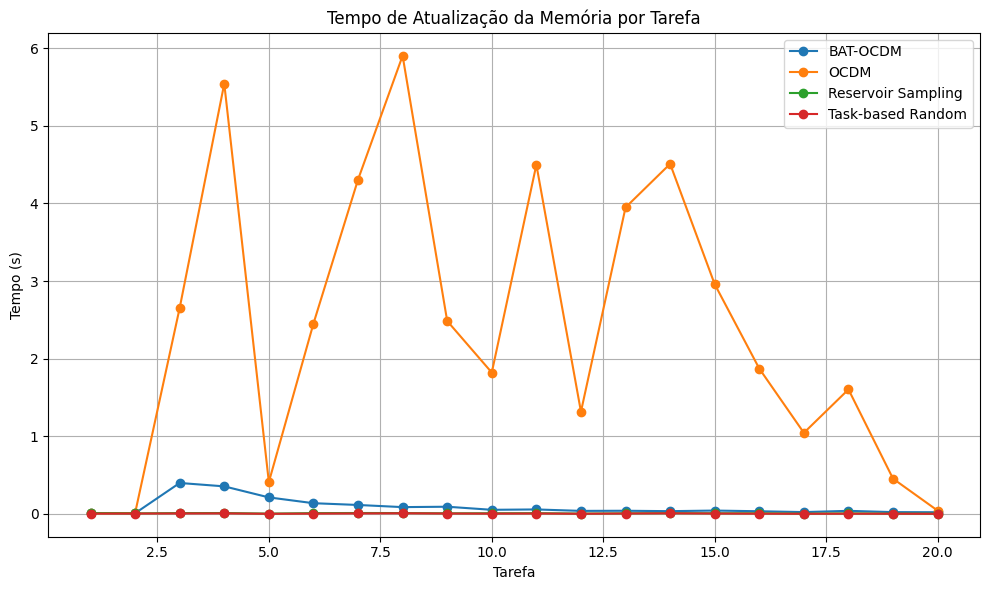

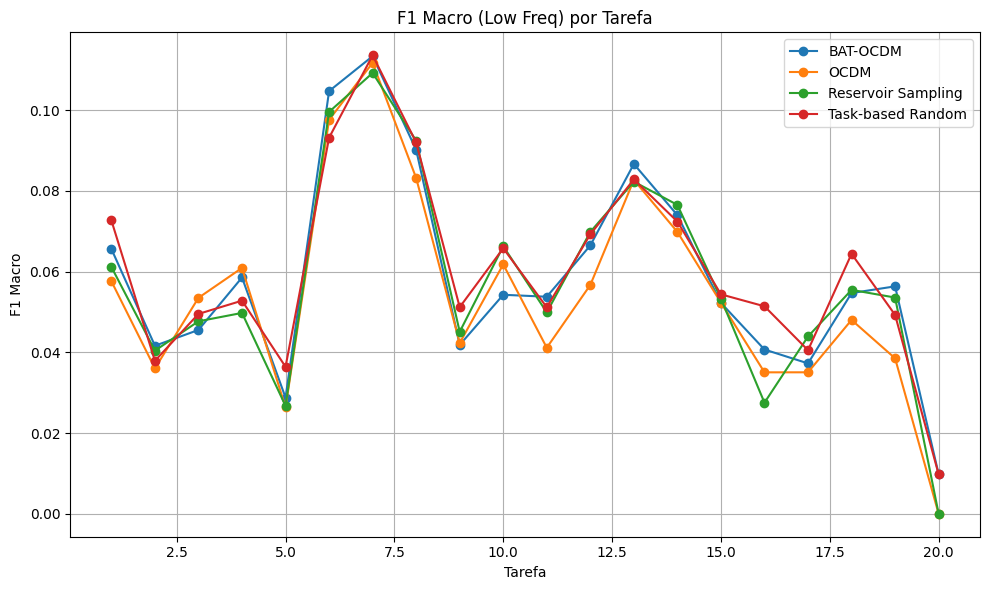

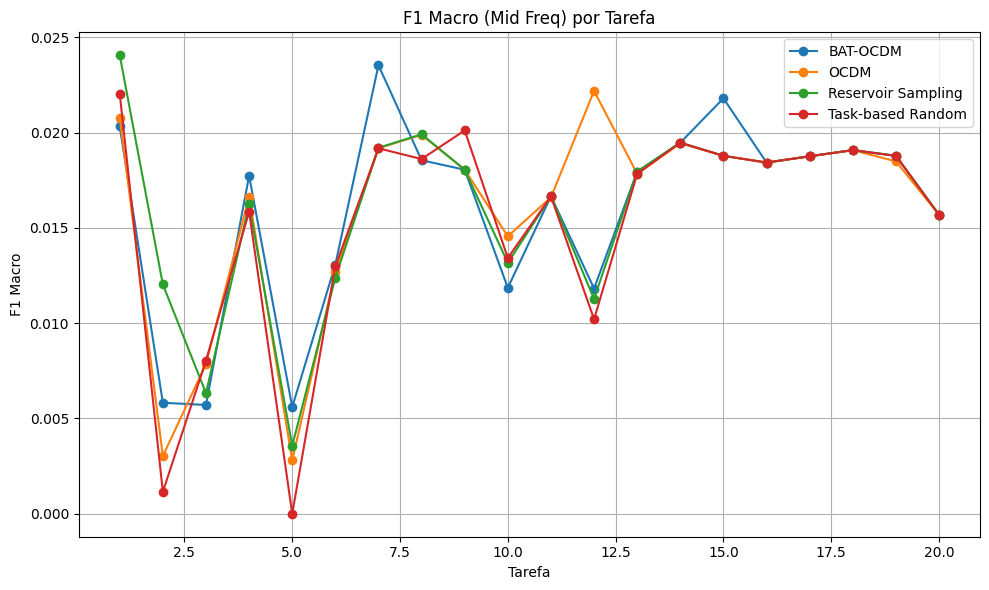

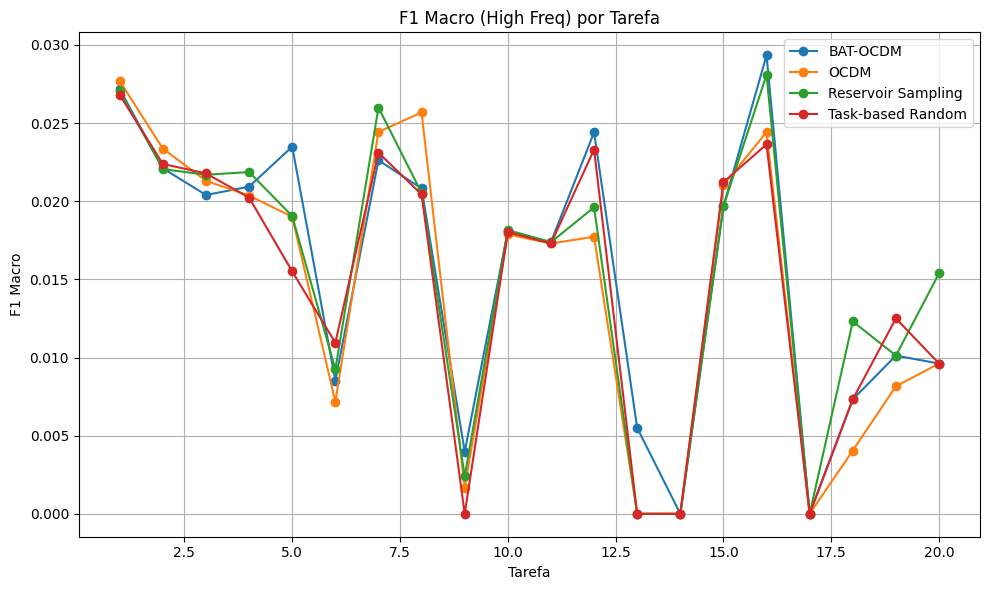

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo=0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        hparams = hparams or {}
        activation = hparams.get('hp_activation', 'tanh')
        dropout_rate = hparams.get('hp_dropout_rate', 0.5)
        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
            nn.Linear(alarm_num_in, 512),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(128, alarm_num_out or alarm_num_in),
            nn.Sigmoid()
        )

        self.optimizer = optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

    def forward(self, X):
        return self.net(X)

    def train_step(self, batch_data, memory_batch_size, device):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)
        sample = sample.to(device)
        y_true = y_true.to(device)

        y_pred = self.net(sample)
        loss = torch.mean(self.criterion(y_pred, y_true))

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)
        self.optimizer.step()

        return loss.item()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = batch_size - new_data_batch_size

        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        times = {"before_training_time": time.time() - start}

        history = {'loss': []}
        train_start = time.time()

        for epoch in range(epochs):
            self.net.train()
            epoch_loss = []

            for batch_data in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
                loss = self.train_step(batch_data, old_data_batch_size, device)
                epoch_loss.append(loss)

            avg_loss = np.mean(epoch_loss)
            history['loss'].append(avg_loss)

        times["train_time"] = time.time() - train_start

        mem_start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        times["add_data_to_memory_time"] = time.time() - mem_start

        return history, times

    def summary(self):
        print(self.net)

class BasePlugin:
    def __init__(self, mem_size, device):
        self.mem_size = mem_size
        self.device = device
        self.x_memory = []
        self.y_memory = []
        self.x_tasks_memory = []
        self.y_tasks_memory = []

    def before_training(self, dataset):
        return DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)

class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0
        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho = 0
        self.target_count = None
        self.target_distribution = None

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = random.sample(range(len(self.x_memory)), memory_batch_size)
            x_selected = torch.tensor(
                np.array([self.x_memory[i] for i in indices]),
                device=self.device
            )
            y_selected = torch.tensor(
                np.array([self.y_memory[i] for i in indices]),
                device=self.device
            )
            return x_selected, y_selected
        else:
            return None, None

    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_mem, y_mem = self._get_sample_from_memory(memory_batch_size)
        x_batch = batch_data[0].to(self.device)
        y_batch = batch_data[1].to(self.device).float()

        if x_mem is not None:
            x_batch = torch.cat((x_batch, x_mem), dim=0)
            y_batch = torch.cat((y_batch, y_mem.float()), dim=0)

        perm = torch.randperm(x_batch.size(0))
        return x_batch[perm], y_batch[perm]

    def update_target_distribution(self, y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = torch.zeros(num_labels, device=self.device)
            self.dataset_count = torch.zeros(num_labels, device=self.device)
            self.target_distribution = torch.zeros(num_labels, device=self.device)

        self.dataset_count += y_batch.sum(dim=0)
        self.num_samples_seen += y_batch.size(0)
        self.num_labels_seen += y_batch.sum()
        self.target_distribution = (self.dataset_count ** self.rho) / (self.num_labels_seen + 1e-8)
        self.target_count = self.target_distribution * self.num_samples_seen

class OCDM_Plugin(RehearsalPlugin):
    def add_data_to_memory(self, train_dataloader, dist_fn):
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            self.update_target_distribution(y_batch)
            memory_update(
                self.target_distribution.cpu().numpy(),
                x_batch.cpu().numpy(),
                y_batch.cpu().numpy(),
                self.x_memory,
                self.y_memory,
                dist_fn,
                self.mem_size,
                self.tasks_in_mem,
                self.task_number
            )
        self.task_number += 1

class BAT_OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)
        all_x = []
        all_y = []

        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            all_x.append(x_batch.cpu().numpy())
            all_y.append(y_batch.cpu().numpy())

        x_all = np.concatenate(all_x)
        y_all = np.concatenate(all_y)

        self.update_target_distribution(torch.tensor(y_all, device=self.device))
        x_list = []
        y_list = []
        memory_update(
            self.target_distribution.cpu().numpy(),
            x_all,
            y_all,
            x_list,
            y_list,
            dist_fn,
            mem_size
        )

        self.x_tasks_memory.append(np.array(x_list))
        self.y_tasks_memory.append(np.array(y_list))

        # Resize anteriores
        for i in range(len(self.x_tasks_memory)):
            x_i, y_i = rehearsal_memory_resize(
                self.target_distribution.cpu().numpy(),
                self.x_tasks_memory[i],
                self.y_tasks_memory[i],
                dist_fn,
                mem_size
            )
            self.x_tasks_memory[i] = x_i
            self.y_tasks_memory[i] = y_i

        self.x_memory = np.concatenate(self.x_tasks_memory, axis=0)
        self.y_memory = np.concatenate(self.y_tasks_memory, axis=0)

class ReservoirSampling_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.total_samples_seen = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].cpu().numpy()
            y_batch = batch_data[1].cpu().numpy()
            for i in range(x_batch.shape[0]):
                self.total_samples_seen += 1
                if len(self.x_memory) < self.mem_size:
                    self.x_memory.append(x_batch[i])
                    self.y_memory.append(y_batch[i])
                    self.tasks_in_mem.append(self.num_tasks)
                else:
                    j = random.randint(0, self.total_samples_seen - 1)
                    if j < self.mem_size:
                        self.x_memory[j] = x_batch[i]
                        self.y_memory[j] = y_batch[i]
                        self.tasks_in_mem[j] = self.num_tasks

class task_based_random_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)

        # Resize old memories
        for i in range(len(self.x_tasks_memory)):
            if len(self.x_tasks_memory[i]) > mem_size:
                indices = np.random.choice(len(self.x_tasks_memory[i]), mem_size, replace=False)
                self.x_tasks_memory[i] = self.x_tasks_memory[i][indices]
                self.y_tasks_memory[i] = self.y_tasks_memory[i][indices]

        # Add new task data
        x_task_data = []
        y_task_data = []
        for _, batch_data in enumerate(train_dataloader):
            x_task_data.append(batch_data[0].cpu().numpy())
            y_task_data.append(batch_data[1].cpu().numpy())

        x_all = np.concatenate(x_task_data)
        y_all = np.concatenate(y_task_data)

        if len(x_all) > mem_size:
            indices = np.random.choice(len(x_all), mem_size, replace=False)
            self.x_tasks_memory.append(x_all[indices])
            self.y_tasks_memory.append(y_all[indices])
        else:
            self.x_tasks_memory.append(x_all)
            self.y_tasks_memory.append(y_all)

        # Combine all memories
        self.x_memory = np.concatenate(self.x_tasks_memory, axis=0)
        self.y_memory = np.concatenate(self.y_tasks_memory, axis=0)


def cast_labels(y_true, y_pred):
    return y_true.float(), torch.clamp(y_pred, EPS, 1-EPS)

def get_WFL(alpha, gamma):
    def WFL(y_pred, y_true):
        y_true, y_pred = cast_labels(y_true, y_pred)
        loss_pos = -alpha * torch.pow(1 - y_pred, gamma) * y_true * torch.log(y_pred)
        loss_neg = -(1-alpha) * torch.pow(y_pred, gamma) * (1 - y_true) * torch.log(1 - y_pred)
        return torch.mean(loss_pos + loss_neg)
    return WFL

def get_activation(name):
    activations = {
        'relu': nn.ReLU(),
        'tanh': nn.Tanh(),
        'sigmoid': nn.Sigmoid()
    }
    return activations.get(name, nn.Tanh())  # Default to tanh

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def labels_count(data_sample):
    return np.count_nonzero(data_sample, axis=0)

def label_distribution(data_sample, rho=1):
    count_alarms = np.sum(data_sample, axis=0)
    count_alarms = count_alarms ** rho
    return count_alarms / (np.sum(count_alarms) + 1e-8)

def min_index(target_distribution, data, dist_fn):
    min_dist = float("inf")
    min_idx = -1
    total_labels = np.sum(data, axis=0)

    for j in range(data.shape[0]):
        candidate = total_labels - data[j]
        prob_distribution = candidate / (np.sum(candidate) + 1e-8)
        dist = dist_fn(prob_distribution, target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_idx = j
    return min_idx

def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size=500, tasks_in_mem=None, task_number=None):
    x_batch = np.array(x_batch)
    y_batch = np.array(y_batch)
    batch_size = y_batch.shape[0]
    remaining_size = mem_size - len(x_memory)

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        indices = np.random.choice(batch_size, size_sample, replace=False)
        for i in indices:
            x_memory.append(x_batch[i])
            y_memory.append(y_batch[i])
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
    else:
        x_omega = np.concatenate([x_memory, x_batch])
        y_omega = np.concatenate([y_memory, y_batch])

        for _ in range(batch_size):
            idx = min_index(target_distribution, y_omega, dist_fn)
            x_omega = np.delete(x_omega, idx, axis=0)
            y_omega = np.delete(y_omega, idx, axis=0)
            if tasks_in_mem is not None and idx < mem_size:
                tasks_in_mem[idx] = task_number

        # Update memory in-place
        x_memory.clear()
        y_memory.clear()
        x_memory.extend(x_omega[:mem_size])
        y_memory.extend(y_omega[:mem_size])

def rehearsal_memory_resize(target_distribution, x_memory, y_memory, dist_fn, new_mem_size=500):
    if len(x_memory) <= new_mem_size:
        return x_memory, y_memory

    items_to_remove = len(x_memory) - new_mem_size
    x_omega = np.array(x_memory)
    y_omega = np.array(y_memory)

    for _ in range(items_to_remove):
        idx = min_index(target_distribution, y_omega, dist_fn)
        x_omega = np.delete(x_omega, idx, axis=0)
        y_omega = np.delete(y_omega, idx, axis=0)

    return x_omega, y_omega

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution

def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

def carregar_dados_alarms_csv(caminho_alarms='./alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas), dtype=torch.float32)
            y_task = torch.tensor(np.array(saidas), dtype=torch.float32)
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

def evaluate_model(model, dataset, device):
    model.eval()
    all_preds = []
    all_labels = []
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro

def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

if __name__ == "__main__":
    import torch.multiprocessing as mp
    mp.set_start_method("spawn", force=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
    mem_size = 400

    strategies = {
        "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
        "OCDM": OCDM_Plugin(mem_size, device),
        "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
        "Task-based Random": task_based_random_Plugin(mem_size, device)
    }

    all_times_per_strategy = {name: [] for name in strategies}
    all_f1_grouped_per_strategy = {name: {'Low': [], 'Mid': [], 'High': []} for name in strategies}

    for strategy_name, plugin in strategies.items():
        print(f"\n=== Estratégia {strategy_name} ===")
        model = ASC_BR_Multilabel_Rehearsal(
            None,
            input_dim,
            plugin,
            hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}
        ).to(device)

        for i, task in enumerate(tasks):
            print(f"\n-- Tarefa {i+1} --")
            history, times = model.fit(
                epochs=5,
                train_dataset=task,
                batch_size=64,
                dist_fn=safe_kl,
                device=device
            )
            all_times_per_strategy[strategy_name].append(times)

            # Avaliação
            X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
            with torch.no_grad():
                outputs = model(X)
                preds = (outputs > 0.5).float().cpu().numpy()
                labels = Y.cpu().numpy()

            # Cálculo F1 por grupos
            num_labels = labels.shape[1]
            group_size = num_labels // 3
            f1_low = f1_score(labels[:, :group_size], preds[:, :group_size], average='macro', zero_division=0)
            f1_mid = f1_score(labels[:, group_size:2*group_size], preds[:, group_size:2*group_size], average='macro', zero_division=0)
            f1_high = f1_score(labels[:, 2*group_size:], preds[:, 2*group_size:], average='macro', zero_division=0)

            all_f1_grouped_per_strategy[strategy_name]['Low'].append(f1_low)
            all_f1_grouped_per_strategy[strategy_name]['Mid'].append(f1_mid)
            all_f1_grouped_per_strategy[strategy_name]['High'].append(f1_high)

    # Plotting
    task_numbers = list(range(1, len(tasks)+1))

    # Tempo de atualização da memória
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
        plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
    plt.title('Tempo de Atualização da Memória por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('Tempo (s)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # F1 por frequência
    for group in ['Low', 'Mid', 'High']:
        plt.figure(figsize=(10, 6))
        for strategy_name in strategies:
            plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
        plt.title(f'F1 Macro ({group} Freq) por Tarefa')
        plt.xlabel('Tarefa')
        plt.ylabel('F1 Macro')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --


100%|██████████| 3/3 [00:00<00:00, 829.84it/s]



-- Tarefa 2 --


100%|██████████| 4/4 [00:00<00:00, 834.36it/s]



-- Tarefa 3 --


100%|██████████| 5/5 [00:00<00:00, 1030.74it/s]


... (150 outputs left out)


-- Tarefa 19 --


Epoch 5/5: 100%|██████████| 1/1 [00:00<00:00, 72.44it/s]



-- Tarefa 20 --


Epoch 5/5: 100%|██████████| 1/1 [00:00<00:00, 76.07it/s]


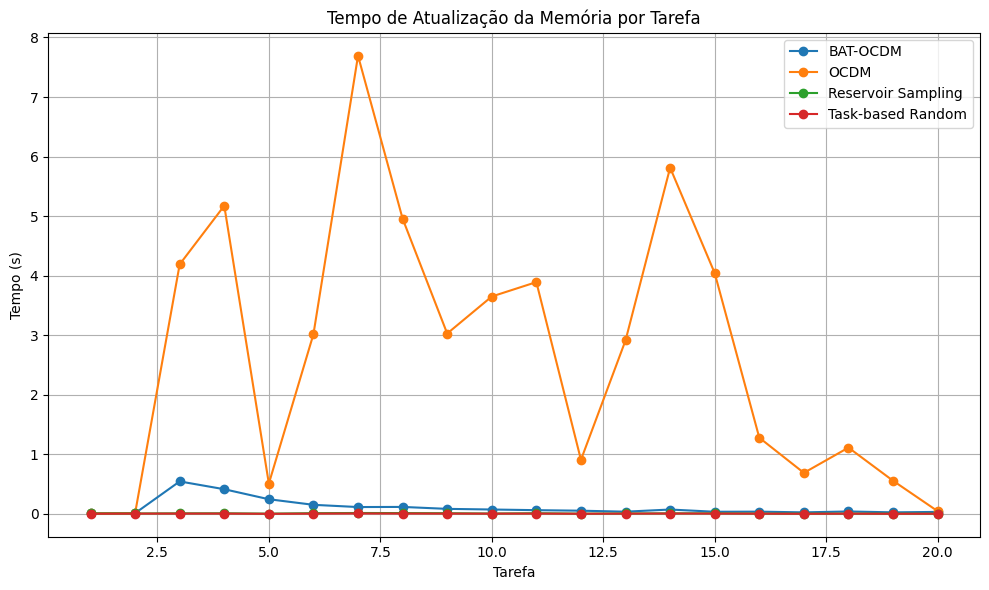

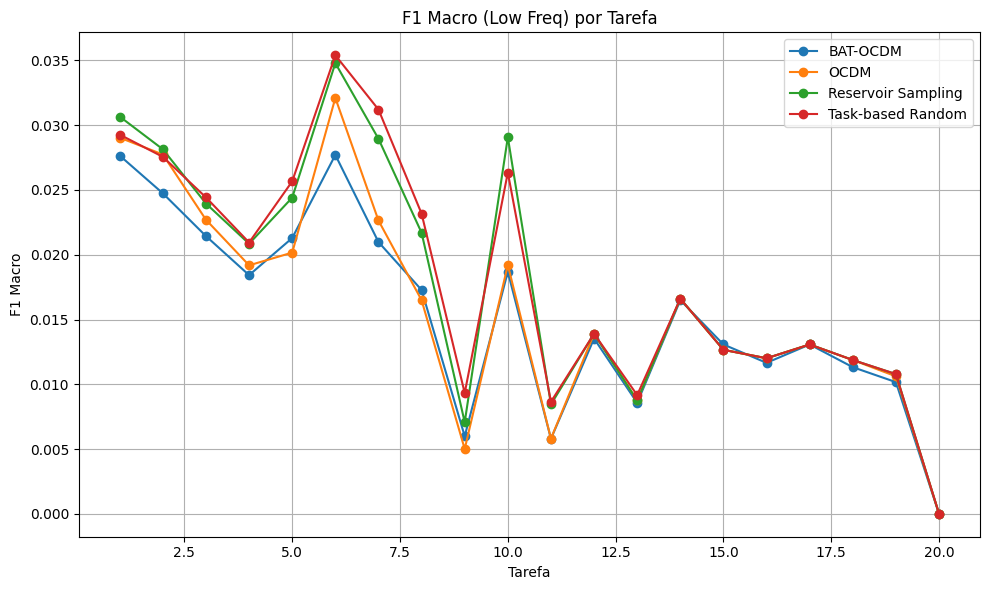

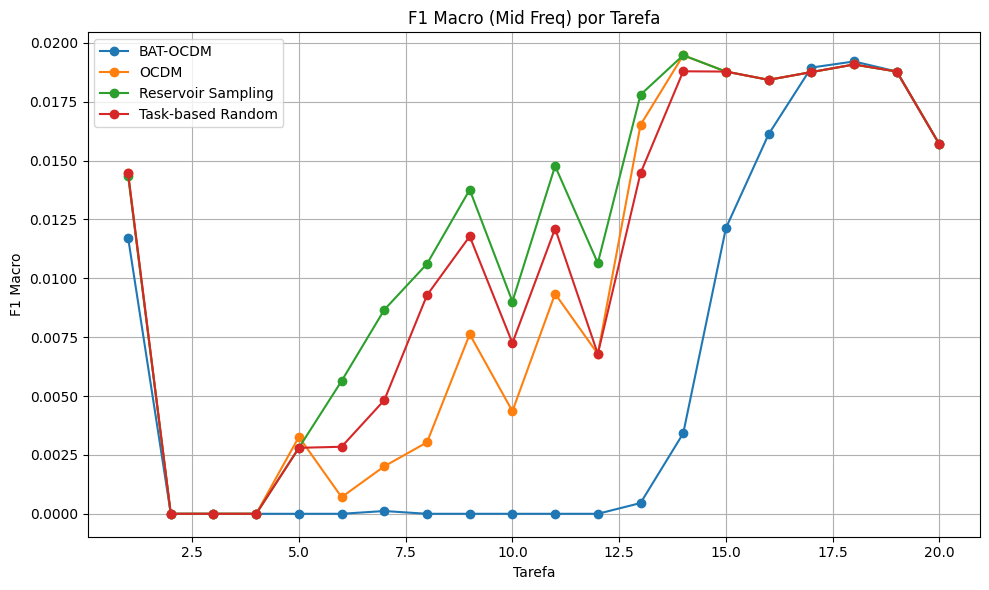

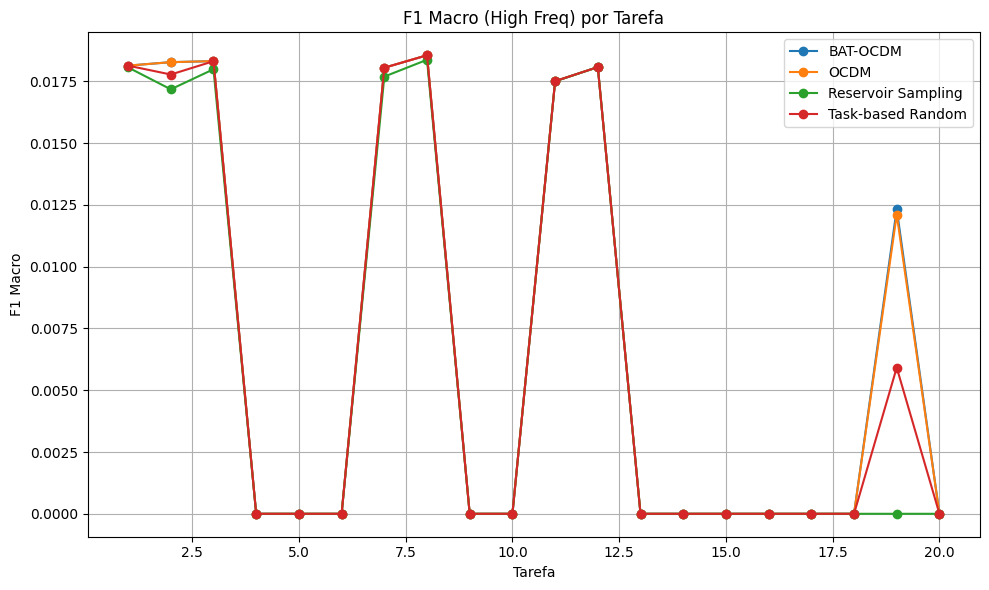

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import warnings
import sys
import time
import random
import sklearn
from tqdm import tqdm
from torchsummary import summary
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset
from datetime import timedelta
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import entropy
from collections import defaultdict
import copy

EPS = 1e-07

class ASC_BR_Multilabel_Rehearsal(nn.Module):
    def __init__(self, Tx, alarm_num_in, plugin, rateo=0.5, alarm_num_out=None, hparams=None):
        super().__init__()
        hparams = hparams or {}
        activation = hparams.get('hp_activation', 'tanh')
        dropout_rate = hparams.get('hp_dropout_rate', 0.5)
        self.alarm_num_in = alarm_num_in

        self.net = nn.Sequential(
            nn.Linear(alarm_num_in, 512),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),
            get_activation(activation),
            nn.Dropout(dropout_rate),
            nn.Linear(128, alarm_num_out or alarm_num_in),
            nn.Sigmoid()
        )

        self.optimizer = optim.Adam(self.net.parameters(), lr=0.001)
        self.criterion = get_WFL(0.8, 2.0)
        self.rateo = rateo
        self.plugin = plugin

         # New additions for Continual G-Learning inspired approach
        self.teacher_model = None
        self.offline_rules = self.load_offline_rules() # Load rules from a file/config
        self.lambda_distill = 1.5 # Hyperparameter
        self.lambda_rules = 0.5  # Hyperparameter

    def forward(self, X):
        return self.net(X)

    def load_offline_rules(self):
    # Example: [(trigger_idx, expected_idx, probability)]
        return [(15, 22, 0.9), (4, 10, 0.75)]

    def train_step(self, batch_data, memory_batch_size, device):
        sample, y_true = self.plugin.train_step_create_batch_data(batch_data, memory_batch_size)
        sample = sample.to(device)
        y_true = y_true.to(device)

        student_logits = self.net(sample)
        y_pred_probs = torch.sigmoid(student_logits) # Probs for WFL and rule loss

        # 1. Standard Classification Loss
        loss_wfl = torch.mean(self.criterion(y_pred_probs, y_true))
        total_loss = loss_wfl

        # 2. Online Prior: Knowledge Distillation Loss
        if self.teacher_model is not None:
            with torch.no_grad():
                teacher_logits = self.teacher_model(sample)

            loss_distill = distillation_loss(student_logits, teacher_logits)
            total_loss += self.lambda_distill * loss_distill

        # 3. Offline Prior: Rule-Based Loss
        if self.offline_rules:
            loss_rules = rule_based_loss(y_pred_probs, sample, self.offline_rules)
            total_loss += self.lambda_rules * loss_rules

        self.optimizer.zero_grad()
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)
        self.optimizer.step()

        return total_loss.item()

    def fit(self, epochs, train_dataset, batch_size, dist_fn, device):
        new_data_batch_size = int(batch_size * self.rateo)
        old_data_batch_size = batch_size - new_data_batch_size

        start = time.time()
        train_dataloader = self.plugin.before_training(train_dataset)
        times = {"before_training_time": time.time() - start}

        history = {'loss': []}
        train_start = time.time()

        for epoch in range(epochs):
            self.net.train()
            epoch_loss = []

            for batch_data in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
                loss = self.train_step(batch_data, old_data_batch_size, device)
                epoch_loss.append(loss)

            avg_loss = np.mean(epoch_loss)
            history['loss'].append(avg_loss)

        times["train_time"] = time.time() - train_start

        mem_start = time.time()
        self.plugin.add_data_to_memory(train_dataloader, dist_fn)
        times["add_data_to_memory_time"] = time.time() - mem_start

        self.teacher_model = copy.deepcopy(self.net)
        self.teacher_model.eval() # Put teacher in evaluation mode

        return history, times

    def summary(self):
        print(self.net)

class BasePlugin:
    def __init__(self, mem_size, device):
        self.mem_size = mem_size
        self.device = device
        self.x_memory = []
        self.y_memory = []
        self.x_tasks_memory = []
        self.y_tasks_memory = []

    def before_training(self, dataset):
        return DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)

class RehearsalPlugin(BasePlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.tasks_in_mem = []
        self.task_number = 0
        self.dataset_count = None
        self.num_samples_seen = 0
        self.num_labels_seen = 0
        self.rho = 0
        self.target_count = None
        self.target_distribution = None

    def _get_sample_from_memory(self, memory_batch_size):
        if len(self.x_memory) >= memory_batch_size:
            indices = random.sample(range(len(self.x_memory)), memory_batch_size)
            x_selected = torch.tensor(
                np.array([self.x_memory[i] for i in indices]),
                device=self.device
            )
            y_selected = torch.tensor(
                np.array([self.y_memory[i] for i in indices]),
                device=self.device
            )
            return x_selected, y_selected
        else:
            return None, None

    def train_step_create_batch_data(self, batch_data, memory_batch_size):
        x_mem, y_mem = self._get_sample_from_memory(memory_batch_size)
        x_batch = batch_data[0].to(self.device)
        y_batch = batch_data[1].to(self.device).float()

        if x_mem is not None:
            x_batch = torch.cat((x_batch, x_mem), dim=0)
            y_batch = torch.cat((y_batch, y_mem.float()), dim=0)

        perm = torch.randperm(x_batch.size(0))
        return x_batch[perm], y_batch[perm]

    def update_target_distribution(self, y_batch):
        if self.target_count is None:
            num_labels = y_batch.shape[1]
            self.target_count = torch.zeros(num_labels, device=self.device)
            self.dataset_count = torch.zeros(num_labels, device=self.device)
            self.target_distribution = torch.zeros(num_labels, device=self.device)

        # Increase rho for low-frequency alarms
        self.rho = 1.2 if "low_freq_dominant" else 0.8  # Context-aware

        self.dataset_count += y_batch.sum(dim=0)
        self.num_samples_seen += y_batch.size(0)
        self.num_labels_seen += y_batch.sum()
        self.target_distribution = (self.dataset_count ** self.rho) / (self.num_labels_seen + 1e-8)
        self.target_count = self.target_distribution * self.num_samples_seen

class OCDM_Plugin(RehearsalPlugin):
    def add_data_to_memory(self, train_dataloader, dist_fn):
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            self.update_target_distribution(y_batch)
            memory_update(
                self.target_distribution.cpu().numpy(),
                x_batch.cpu().numpy(),
                y_batch.cpu().numpy(),
                self.x_memory,
                self.y_memory,
                dist_fn,
                self.mem_size,
                self.tasks_in_mem,
                self.task_number
            )
        self.task_number += 1

class BAT_OCDM_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)
        all_x = []
        all_y = []

        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].to(self.device)
            y_batch = batch_data[1].to(self.device).float()
            all_x.append(x_batch.cpu().numpy())
            all_y.append(y_batch.cpu().numpy())

        x_all = np.concatenate(all_x)
        y_all = np.concatenate(all_y)

        self.update_target_distribution(torch.tensor(y_all, device=self.device))
        x_list = []
        y_list = []
        memory_update(
            self.target_distribution.cpu().numpy(),
            x_all,
            y_all,
            x_list,
            y_list,
            dist_fn,
            mem_size
        )

        self.x_tasks_memory.append(np.array(x_list))
        self.y_tasks_memory.append(np.array(y_list))

        # Resize anteriores
        for i in range(len(self.x_tasks_memory)):
            x_i, y_i = rehearsal_memory_resize(
                self.target_distribution.cpu().numpy(),
                self.x_tasks_memory[i],
                self.y_tasks_memory[i],
                dist_fn,
                mem_size
            )
            self.x_tasks_memory[i] = x_i
            self.y_tasks_memory[i] = y_i

        self.x_memory = np.concatenate(self.x_tasks_memory, axis=0)
        self.y_memory = np.concatenate(self.y_tasks_memory, axis=0)

class ReservoirSampling_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0
        self.total_samples_seen = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        for _, batch_data in tqdm(enumerate(train_dataloader), total=len(train_dataloader)):
            x_batch = batch_data[0].cpu().numpy()
            y_batch = batch_data[1].cpu().numpy()
            for i in range(x_batch.shape[0]):
                self.total_samples_seen += 1
                if len(self.x_memory) < self.mem_size:
                    self.x_memory.append(x_batch[i])
                    self.y_memory.append(y_batch[i])
                    self.tasks_in_mem.append(self.num_tasks)
                else:
                    j = random.randint(0, self.total_samples_seen - 1)
                    if j < self.mem_size:
                        self.x_memory[j] = x_batch[i]
                        self.y_memory[j] = y_batch[i]
                        self.tasks_in_mem[j] = self.num_tasks

class task_based_random_Plugin(RehearsalPlugin):
    def __init__(self, mem_size, device):
        super().__init__(mem_size, device)
        self.num_tasks = 0

    def add_data_to_memory(self, train_dataloader, dist_fn):
        self.num_tasks += 1
        mem_size = round(self.mem_size / self.num_tasks)

        # Resize old memories
        for i in range(len(self.x_tasks_memory)):
            if len(self.x_tasks_memory[i]) > mem_size:
                indices = np.random.choice(len(self.x_tasks_memory[i]), mem_size, replace=False)
                self.x_tasks_memory[i] = self.x_tasks_memory[i][indices]
                self.y_tasks_memory[i] = self.y_tasks_memory[i][indices]

        # Add new task data
        x_task_data = []
        y_task_data = []
        for _, batch_data in enumerate(train_dataloader):
            x_task_data.append(batch_data[0].cpu().numpy())
            y_task_data.append(batch_data[1].cpu().numpy())

        x_all = np.concatenate(x_task_data)
        y_all = np.concatenate(y_task_data)

        if len(x_all) > mem_size:
            indices = np.random.choice(len(x_all), mem_size, replace=False)
            self.x_tasks_memory.append(x_all[indices])
            self.y_tasks_memory.append(y_all[indices])
        else:
            self.x_tasks_memory.append(x_all)
            self.y_tasks_memory.append(y_all)

        # Combine all memories
        self.x_memory = np.concatenate(self.x_tasks_memory, axis=0)
        self.y_memory = np.concatenate(self.y_tasks_memory, axis=0)


def distillation_loss(student_logits, teacher_logits, temperature=2.0):
    """
    Calculates the distillation loss (KL Divergence).
    """
    soft_student_log = F.log_softmax(student_logits / temperature, dim=1)
    soft_teacher_prob = F.softmax(teacher_logits / temperature, dim=1)

    loss = F.kl_div(soft_student_log, soft_teacher_prob, reduction='batchmean') * (temperature**2)
    return loss

def rule_based_loss(y_pred_probs, x_batch, rules):
    """
    Calculates a penalty for violating pre-defined offline rules.
    y_pred_probs are the sigmoid probabilities from the model.
    """
    rule_penalty = 0.0
    num_triggered = 0

    for trigger_idx, expected_idx, prob in rules:
        # Find all samples in the batch where the trigger alarm is present
        triggered_samples_mask = (x_batch[:, trigger_idx] == 1)

        if triggered_samples_mask.any():
            # Get the model's predicted probability for the expected alarm
            predicted_probs_for_rule = y_pred_probs[triggered_samples_mask, expected_idx]

            # Calculate a penalty (e.g., MSE from the target probability)
            penalty_for_this_rule = torch.mean((predicted_probs_for_rule - prob) ** 2)
            rule_penalty += penalty_for_this_rule
            num_triggered += 1

    return rule_penalty / (num_triggered + 1e-8) # Average penalty over triggered rules


def cast_labels(y_true, y_pred):
    return y_true.float(), torch.clamp(y_pred, EPS, 1-EPS)

def get_WFL(alpha, gamma):
    def WFL(y_pred, y_true):
        y_true, y_pred = cast_labels(y_true, y_pred)
        loss_pos = -alpha * torch.pow(1 - y_pred, gamma) * y_true * torch.log(y_pred)
        loss_neg = -(1-alpha) * torch.pow(y_pred, gamma) * (1 - y_true) * torch.log(1 - y_pred)
        return torch.mean(loss_pos + loss_neg)
    return WFL

def get_activation(name):
    activations = {
        'relu': nn.ReLU(),
        'tanh': nn.Tanh(),
        'sigmoid': nn.Sigmoid()
    }
    return activations.get(name, nn.Tanh())  # Default to tanh

def print_time_taken(start, end):
    seconds = end - start
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{minutes}m {seconds}s"

def labels_count(data_sample):
    return np.count_nonzero(data_sample, axis=0)

def label_distribution(data_sample, rho=1):
    count_alarms = np.sum(data_sample, axis=0)
    count_alarms = count_alarms ** rho
    return count_alarms / (np.sum(count_alarms) + 1e-8)

def min_index(target_distribution, data, dist_fn):
    min_dist = float("inf")
    min_idx = -1
    total_labels = np.sum(data, axis=0)

    for j in range(data.shape[0]):
        candidate = total_labels - data[j]
        prob_distribution = candidate / (np.sum(candidate) + 1e-8)
        dist = dist_fn(prob_distribution, target_distribution)
        if dist < min_dist:
            min_dist = dist
            min_idx = j
    return min_idx

def memory_update(target_distribution, x_batch, y_batch, x_memory, y_memory, dist_fn, mem_size=500, tasks_in_mem=None, task_number=None):
    x_batch = np.array(x_batch)
    y_batch = np.array(y_batch)
    batch_size = y_batch.shape[0]
    remaining_size = mem_size - len(x_memory)

    if remaining_size > 0:
        size_sample = min(remaining_size, batch_size)
        indices = np.random.choice(batch_size, size_sample, replace=False)
        for i in indices:
            x_memory.append(x_batch[i])
            y_memory.append(y_batch[i])
            if tasks_in_mem is not None:
                tasks_in_mem.append(task_number)
    else:
        x_omega = np.concatenate([x_memory, x_batch])
        y_omega = np.concatenate([y_memory, y_batch])

        for _ in range(batch_size):
            idx = min_index(target_distribution, y_omega, dist_fn)
            x_omega = np.delete(x_omega, idx, axis=0)
            y_omega = np.delete(y_omega, idx, axis=0)
            if tasks_in_mem is not None and idx < mem_size:
                tasks_in_mem[idx] = task_number

        # Update memory in-place
        x_memory.clear()
        y_memory.clear()
        x_memory.extend(x_omega[:mem_size])
        y_memory.extend(y_omega[:mem_size])

def rehearsal_memory_resize(target_distribution, x_memory, y_memory, dist_fn, new_mem_size=500):
    if len(x_memory) <= new_mem_size:
        return x_memory, y_memory

    items_to_remove = len(x_memory) - new_mem_size
    x_omega = np.array(x_memory)
    y_omega = np.array(y_memory)

    for _ in range(items_to_remove):
        idx = min_index(target_distribution, y_omega, dist_fn)
        x_omega = np.delete(x_omega, idx, axis=0)
        y_omega = np.delete(y_omega, idx, axis=0)

    return x_omega, y_omega

def plot_task_distribution(tasks_memory, strategy_name):
    num_tasks = len(tasks_memory)
    memory_size_per_task = [len(task_memory) for task_memory in tasks_memory]

    plt.figure(figsize=(8, 5))
    plt.bar(range(num_tasks), memory_size_per_task)
    plt.axhline(y=np.mean(memory_size_per_task), color='k', linestyle='--')
    plt.xlabel('Tarefa')
    plt.ylabel('Tamanho da memória')
    plt.title(f'Distribuição de Memória por Tarefa ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_label_distribution(y_memory, strategy_name):
    if not y_memory or all(len(task) == 0 for task in y_memory):
        print(f"[Aviso] Memória vazia para {strategy_name}. Pulando plot de labels.")
        return None

    all_labels = torch.cat([
        torch.stack([torch.tensor(sample) for sample in task])
        for task in y_memory if len(task) > 0
    ], dim=0)

    label_counts = all_labels.sum(dim=0).cpu().numpy()
    label_distribution = label_counts / (label_counts.sum() + 1e-8)

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(label_distribution)), label_distribution)
    plt.axhline(y=1/len(label_distribution), color='k', linestyle='--')
    plt.xlabel('Label (alarme)')
    plt.ylabel('Distribuição')
    plt.title(f'Distribuição de Memória por Label ({strategy_name})')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return label_distribution

def calcular_kl_divergence(label_distribution):
    ideal_distribution = np.ones_like(label_distribution) / len(label_distribution)
    kl = entropy(label_distribution + 1e-8, ideal_distribution)
    return kl

def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas), dtype=torch.float32)
            y_task = torch.tensor(np.array(saidas), dtype=torch.float32)
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

def evaluate_model(model, dataset, device):
    model.eval()
    all_preds = []
    all_labels = []
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            outputs = model(X_batch)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_micro = f1_score(all_labels, all_preds, average='micro', zero_division=0)
    return acc, f1_macro, f1_micro

def safe_kl(p, q):
    p = np.asarray(p, dtype=np.float32) + 1e-8
    q = np.asarray(q, dtype=np.float32) + 1e-8
    p /= p.sum()
    q /= q.sum()
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

if __name__ == "__main__":
    import torch.multiprocessing as mp
    mp.set_start_method("spawn", force=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tasks, input_dim = carregar_dados_alarms_csv('/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv')
    mem_size = 400

    strategies = {
        "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
        "OCDM": OCDM_Plugin(mem_size, device),
        "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
        "Task-based Random": task_based_random_Plugin(mem_size, device)
    }

    all_times_per_strategy = {name: [] for name in strategies}
    all_f1_grouped_per_strategy = {name: {'Low': [], 'Mid': [], 'High': []} for name in strategies}

    for strategy_name, plugin in strategies.items():
        print(f"\n=== Estratégia {strategy_name} ===")
        model = ASC_BR_Multilabel_Rehearsal(
            None,
            input_dim,
            plugin,
            hparams={'hp_activation': 'tanh', 'hp_dropout_rate': 0.3}
        ).to(device)

        for i, task in enumerate(tasks):
            print(f"\n-- Tarefa {i+1} --")
            history, times = model.fit(
                epochs=5,
                train_dataset=task,
                batch_size=64,
                dist_fn=safe_kl,
                device=device
            )
            all_times_per_strategy[strategy_name].append(times)

            # Avaliação
            X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
            with torch.no_grad():
                outputs = model(X)
                preds = (outputs > 0.5).float().cpu().numpy()
                labels = Y.cpu().numpy()

            # Cálculo F1 por grupos
            num_labels = labels.shape[1]
            group_size = num_labels // 3
            f1_low = f1_score(labels[:, :group_size], preds[:, :group_size], average='macro', zero_division=0)
            f1_mid = f1_score(labels[:, group_size:2*group_size], preds[:, group_size:2*group_size], average='macro', zero_division=0)
            f1_high = f1_score(labels[:, 2*group_size:], preds[:, 2*group_size:], average='macro', zero_division=0)

            all_f1_grouped_per_strategy[strategy_name]['Low'].append(f1_low)
            all_f1_grouped_per_strategy[strategy_name]['Mid'].append(f1_mid)
            all_f1_grouped_per_strategy[strategy_name]['High'].append(f1_high)

    # Plotting
    task_numbers = list(range(1, len(tasks)+1))

    # Tempo de atualização da memória
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        memory_times = [t["add_data_to_memory_time"] for t in all_times_per_strategy[strategy_name]]
        plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
    plt.title('Tempo de Atualização da Memória por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('Tempo (s)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # F1 por frequência
    for group in ['Low', 'Mid', 'High']:
        plt.figure(figsize=(10, 6))
        for strategy_name in strategies:
            plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
        plt.title(f'F1 Macro ({group} Freq) por Tarefa')
        plt.xlabel('Tarefa')
        plt.ylabel('F1 Macro')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

Encontrados 20 máquinas (serials) e 154 alarmes únicos.

=== Estratégia BAT-OCDM ===

-- Tarefa 1 --

-- Tarefa 2 --

-- Tarefa 3 --

-- Tarefa 4 --

-- Tarefa 5 --

-- Tarefa 6 --

-- Tarefa 7 --

-- Tarefa 8 --

-- Tarefa 9 --

-- Tarefa 10 --

-- Tarefa 11 --

-- Tarefa 12 --

-- Tarefa 13 --

-- Tarefa 14 --

-- Tarefa 15 --

-- Tarefa 16 --

-- Tarefa 17 --

-- Tarefa 18 --

-- Tarefa 19 --

-- Tarefa 20 --

=== Estratégia OCDM ===

-- Tarefa 1 --

-- Tarefa 2 --

-- Tarefa 3 --

-- Tarefa 4 --

-- Tarefa 5 --

-- Tarefa 6 --

-- Tarefa 7 --

-- Tarefa 8 --

-- Tarefa 9 --

-- Tarefa 10 --

-- Tarefa 11 --

-- Tarefa 12 --

-- Tarefa 13 --

-- Tarefa 14 --

-- Tarefa 15 --

-- Tarefa 16 --

-- Tarefa 17 --

-- Tarefa 18 --

-- Tarefa 19 --

-- Tarefa 20 --

=== Estratégia Reservoir Sampling ===

-- Tarefa 1 --

-- Tarefa 2 --

-- Tarefa 3 --

-- Tarefa 4 --

-- Tarefa 5 --

-- Tarefa 6 --

-- Tarefa 7 --

-- Tarefa 8 --

-- Tarefa 9 --

-- Tarefa 10 --

-- Tarefa 11 --

-- Tarefa 

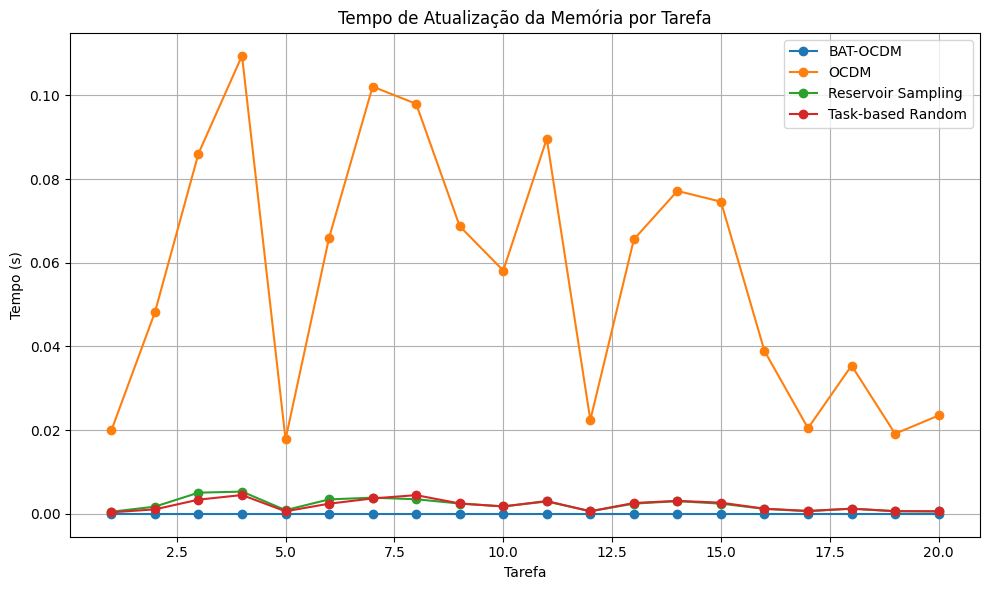

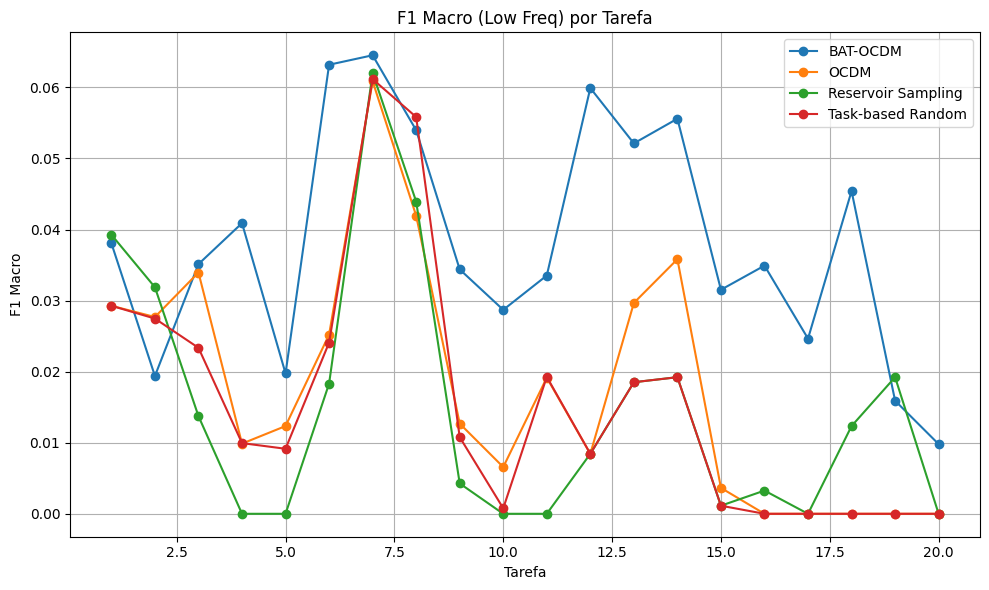

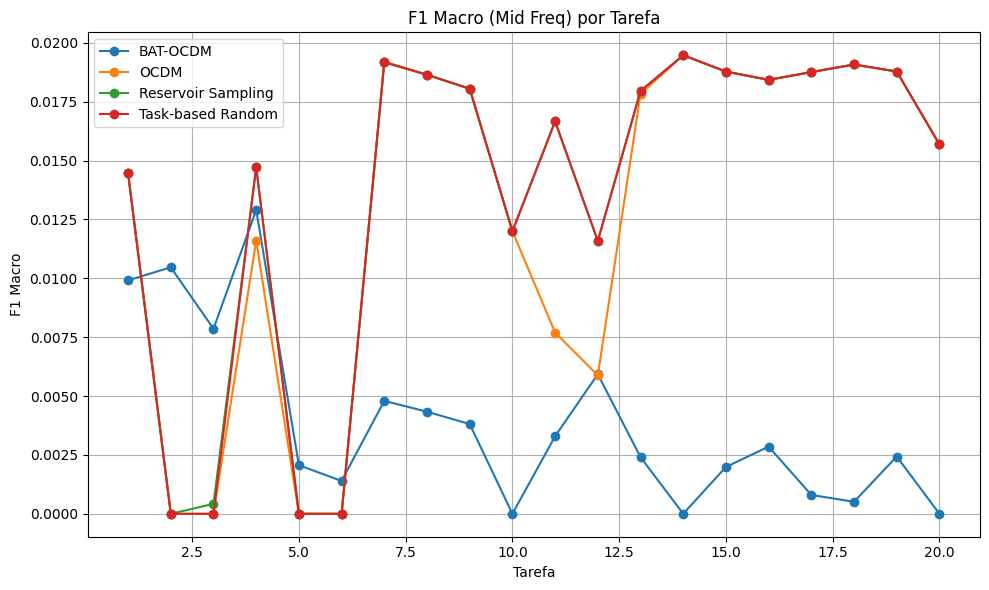

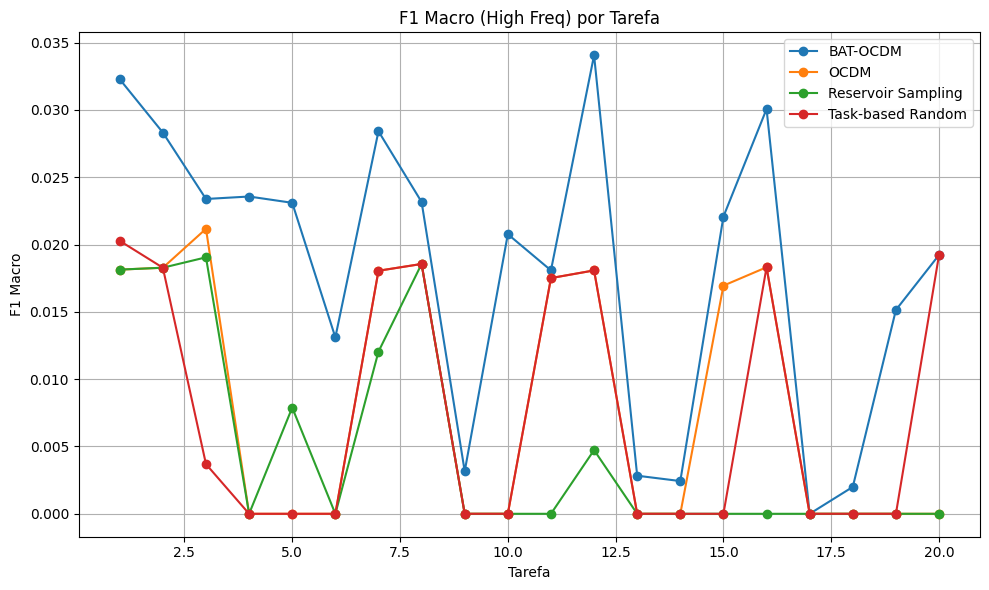

In [ ]:
import math
import time
import numpy as np
import pandas as pd
from datetime import timedelta
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset
from typing import Dict, Iterable, List, Tuple
import matplotlib.pyplot as plt

# ==============================================================
# Utils
# ==============================================================

def moving_ema(prev: float, value: float, alpha: float) -> float:
    return alpha * value + (1 - alpha) * prev

# ==============================================================
# Drift Detector (Alg. 3) — EWMA
# ==============================================================
class DriftDetector:
    def __init__(self, lam: float = 0.2, ARL: int = 500):
        self.lam = lam
        self.ARL = ARL
        self.reset()

    def reset(self):
        self.t = 0
        self.z_t = 0.0
        self.p_hat = 0.0

    @staticmethod
    def _L_from_ARL(ARL: int) -> float:
        if ARL <= 200:
            return 2.7
        if ARL <= 370:
            return 2.9
        if ARL <= 500:
            return 3.0
        if ARL <= 1000:
            return 3.2
        return 3.4

    def update(self, logits: torch.Tensor, y_true: torch.Tensor) -> bool:
        if y_true.ndim == 2 and y_true.size(1) > 1:
            y_idx = y_true.argmax(dim=1)
        else:
            y_idx = y_true.view(-1).long()
        y_pred = logits.argmax(dim=1)
        x_t = (y_pred != y_idx).float().mean().item()

        self.t += 1
        self.p_hat = (self.p_hat * (self.t - 1) + x_t) / self.t
        self.z_t = (1 - self.lam) * self.z_t + self.lam * x_t

        sigma_x = math.sqrt(max(self.p_hat * (1 - self.p_hat), 1e-6))
        sigma_z = math.sqrt(self.lam / (2 - self.lam)) * sigma_x
        L = self._L_from_ARL(self.ARL)
        threshold = self.p_hat + L * sigma_z
        return self.z_t > threshold

# ==============================================================
# Selection strategies for rehearsal memory
# ==============================================================

def herding_selection(features: np.ndarray, labels: np.ndarray, mem_size: int) -> Tuple[np.ndarray, np.ndarray]:
    if features.size == 0:
        return features, labels
    N, C = labels.shape
    selected = []
    per_label_quota = max(1, mem_size // max(1, C))
    f = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-8)
    for c in range(C):
        idx_c = np.where(labels[:, c] > 0.5)[0]
        if len(idx_c) == 0:
            continue
        proto = f[idx_c].mean(axis=0, keepdims=True)
        sims = (f[idx_c] * proto).sum(axis=1)
        order = idx_c[np.argsort(-sims)]
        for k in order[:per_label_quota]:
            if len(selected) >= mem_size:
                break
            selected.append(int(k))
        if len(selected) >= mem_size:
            break
    if len(selected) < mem_size:
        margins = np.abs(features.max(axis=1) - np.partition(features, -2, axis=1)[:, -2])
        extra = np.argsort(margins)
        for k in extra:
            if k in selected:
                continue
            selected.append(int(k))
            if len(selected) >= mem_size:
                break
    sel = np.array(sorted(set(selected)))
    return features[sel], labels[sel]


def reservoir_selection(features: np.ndarray, labels: np.ndarray, mem_size: int) -> Tuple[np.ndarray, np.ndarray]:
    if features.size == 0:
        return features, labels
    N = features.shape[0]
    if N <= mem_size:
        return features, labels
    idx = np.random.choice(N, mem_size, replace=False)
    return features[idx], labels[idx]


def random_selection(features: np.ndarray, labels: np.ndarray, mem_size: int) -> Tuple[np.ndarray, np.ndarray]:
    return reservoir_selection(features, labels, mem_size)

# ==============================================================
# Plugins (common API expected by the trainer)
# ==============================================================
class BasePlugin:
    def __init__(self, mem_size: int, device: torch.device):
        self.mem_size = mem_size
        self.device = device
        self.x_memory: List[np.ndarray] = []
        self.y_memory: List[np.ndarray] = []
        self.Px: List[torch.Tensor] = []
        self.Py: List[torch.Tensor] = []
        # default: only BAT uses EWMA; others will be AlwaysDriftDetector
        self.detector = DriftDetector(lam=0.2, ARL=500)

    def add_to_postponed(self, x: torch.Tensor, y: torch.Tensor):
        self.Px.append(x.detach().cpu())
        self.Py.append(y.detach().cpu())

    def flush_postponed(self) -> Tuple[torch.Tensor, torch.Tensor]:
        if len(self.Px) == 0:
            return torch.empty(0), torch.empty(0)
        x = torch.cat(self.Px, dim=0)
        y = torch.cat(self.Py, dim=0)
        self.Px.clear(); self.Py.clear()
        return x, y

    def rehearsal_numpy(self) -> Tuple[np.ndarray, np.ndarray]:
        if len(self.x_memory) == 0:
            return np.empty((0,)), np.empty((0,))
        return np.stack(self.x_memory, axis=0), np.stack(self.y_memory, axis=0)

    def update_rehearsal(self, feats: np.ndarray, labels: np.ndarray):
        raise NotImplementedError

class BAT_OCDM_Plugin(BasePlugin):
    def __init__(self, mem_size: int, device: torch.device, lam: float = 0.2, ARL: int = 500):
        super().__init__(mem_size, device)
        self.detector = DriftDetector(lam=lam, ARL=ARL)

    def update_rehearsal(self, feats: np.ndarray, labels: np.ndarray):
        if feats.size == 0:
            return
        keep_f, keep_y = herding_selection(feats, labels, self.mem_size)
        self.x_memory = [keep_f[i] for i in range(len(keep_f))]
        self.y_memory = [keep_y[i] for i in range(len(keep_y))]

class OCDM_Plugin(BasePlugin):
    """OCDM baseline: update every batch (no drift gating), herding selection."""
    def update_rehearsal(self, feats: np.ndarray, labels: np.ndarray):
        if feats.size == 0:
            return
        keep_f, keep_y = herding_selection(feats, labels, self.mem_size)
        self.x_memory = [keep_f[i] for i in range(len(keep_f))]
        self.y_memory = [keep_y[i] for i in range(len(keep_y))]

class ReservoirSampling_Plugin(BasePlugin):
    def update_rehearsal(self, feats: np.ndarray, labels: np.ndarray):
        if feats.size == 0:
            return
        keep_f, keep_y = reservoir_selection(feats, labels, self.mem_size)
        self.x_memory = [keep_f[i] for i in range(len(keep_f))]
        self.y_memory = [keep_y[i] for i in range(len(keep_y))]

class task_based_random_Plugin(BasePlugin):
    def update_rehearsal(self, feats: np.ndarray, labels: np.ndarray):
        if feats.size == 0:
            return
        keep_f, keep_y = random_selection(feats, labels, self.mem_size)
        self.x_memory = [keep_f[i] for i in range(len(keep_f))]
        self.y_memory = [keep_y[i] for i in range(len(keep_y))]

# ==============================================================
# Trainer (Alg. 1 + 2)
# ==============================================================
class AdaptiveCLTrainer:
    def __init__(self, net: nn.Module, plugin: BasePlugin, device: torch.device, base_lr: float = 1e-3, rateo: float = 0.5):
        self.net = net.to(device)
        self.device = device
        self.plugin = plugin
        self.base_lr = base_lr
        self.optimizer = optim.Adam(self.net.parameters(), lr=base_lr)
        self.criterion = nn.BCEWithLogitsLoss()
        self.rateo = rateo
        self.ema_short = 0.0
        self.ema_long = 0.0

    def _dynamic_iterations(self) -> int:
        z = abs(getattr(self.plugin.detector, 'z_t', 0.2))
        if z < 0.05:
            return 1
        if z < 0.1:
            return 2
        if z < 0.2:
            return 4
        return 6

    def _adaptive_lr(self):
        z = max(getattr(self.plugin.detector, 'z_t', 0.2), 0.0)
        scale = min(100.0, 5.0 * math.exp(3.0 * z))
        lr = self.base_lr * scale
        for g in self.optimizer.param_groups:
            g["lr"] = lr

    def _early_stop(self, loss_val: float) -> bool:
        self.ema_short = moving_ema(self.ema_short, loss_val, 0.3)
        self.ema_long = moving_ema(self.ema_long, loss_val, 0.05)
        return abs(self.ema_short - self.ema_long) < 1e-4

    def _sgd_step(self, x, y) -> float:
        self.optimizer.zero_grad()
        out = self.net(x)
        loss = self.criterion(out, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)
        self.optimizer.step()
        return out.detach(), float(loss.detach().cpu().item())

    def fit(self, train_dataset: Dataset, batch_size: int, epochs: int):
        dl = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
        history = {"loss": []}
        times: Dict[str, float] = {"add_data_to_memory_time": 0.0}
        t0 = time.time()

        for epoch in range(epochs):
            for xb, yb in dl:
                xb = xb.to(self.device)
                yb = yb.to(self.device).float()
                self.plugin.add_to_postponed(xb, yb)

                with torch.no_grad():
                    logits = self.net(xb)

                # Drift: BAT usa EWMA; baselines atualizam sempre
                if isinstance(self.plugin, BAT_OCDM_Plugin):
                    drift = self.plugin.detector.update(logits, yb)
                else:
                    drift = True

                # inicializa valores padrão
                feats, lbls = np.empty((0,)), np.empty((0,))

                if drift:
                    Px, Py = self.plugin.flush_postponed()
                    Rx_np, Ry_np = self.plugin.rehearsal_numpy()
                    Rx = torch.from_numpy(Rx_np).to(self.device).float() if Rx_np.size else torch.empty(0, device=self.device)
                    Ry = torch.from_numpy(Ry_np).to(self.device).float() if Ry_np.size else torch.empty(0, device=self.device)

                    N = self._dynamic_iterations()
                    self._adaptive_lr()

                    # stream misto
                    def mixed_stream() -> Iterable[Tuple[torch.Tensor, torch.Tensor]]:
                        if Rx.numel() == 0:
                            base = TensorDataset(Px, Py)
                            for x, y in DataLoader(base, batch_size=batch_size, shuffle=True):
                                yield x, y
                            return
                        n_new = int(batch_size * 0.5)
                        n_old = max(1, batch_size - n_new)
                        d_new = DataLoader(TensorDataset(Px, Py), batch_size=n_new, shuffle=True, drop_last=False)
                        d_old = DataLoader(TensorDataset(Rx, Ry), batch_size=n_old, shuffle=True, drop_last=False)
                        it_old = iter(d_old)
                        for x_new, y_new in d_new:
                            try:
                                x_old, y_old = next(it_old)
                            except StopIteration:
                                it_old = iter(d_old)
                                x_old, y_old = next(it_old)
                            yield torch.cat([x_new, x_old], 0), torch.cat([y_new, y_old], 0)

                    for i in range(N):
                        for mix_x, mix_y in mixed_stream():
                            out, loss_val = self._sgd_step(mix_x, mix_y)
                            history["loss"].append(loss_val)
                            if self._early_stop(loss_val):
                                break

                    with torch.no_grad():
                        all_x = torch.cat([Px, Rx], 0) if Rx.numel() else Px
                        all_y = torch.cat([Py, Ry], 0) if Ry.numel() else Py
                        feats = self.net(all_x).detach().cpu().numpy()
                        lbls = all_y.detach().cpu().numpy()

                    mem_t0 = time.time()
                    self.plugin.update_rehearsal(feats, lbls)
                    times["add_data_to_memory_time"] += time.time() - mem_t0

                    if isinstance(self.plugin, BAT_OCDM_Plugin):
                        self.plugin.detector.reset()

        times["total_time"] = time.time() - t0
        return history, times

# ==============================================================
# Simple MLP (you can replace with your ASC_BR network)
# ==============================================================
class SmallMLP(nn.Module):
    def __init__(self, in_dim: int, out_dim: int, hidden: int = 128):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.out = nn.Linear(hidden, out_dim)

    def forward(self, x):
        if x.ndim > 2:
            x = x.view(x.size(0), -1)
        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))
        return self.out(h)

def carregar_dados_alarms_csv(caminho_alarms='/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'):
    df = pd.read_csv(caminho_alarms)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    equipamentos = df['serial'].unique()
    alarmes_unicos = df['alarm'].unique()
    alarme_to_idx = {code: idx for idx, code in enumerate(sorted(alarmes_unicos))}
    num_alarmes = len(alarme_to_idx)
    print(f"Encontrados {len(equipamentos)} máquinas (serials) e {num_alarmes} alarmes únicos.")

    tasks = []
    janela_entrada = timedelta(minutes=1720)
    janela_saida = timedelta(minutes=480)

    for equipamento in sorted(equipamentos):
        df_equip = df[df['serial'] == equipamento].sort_values('timestamp')
        inicio = df_equip['timestamp'].min()
        entradas, saidas = [], []

        while inicio + janela_entrada + janela_saida <= df_equip['timestamp'].max():
            fim_entrada = inicio + janela_entrada
            fim_saida = fim_entrada + janela_saida

            janela_in = df_equip[(df_equip['timestamp'] >= inicio) & (df_equip['timestamp'] < fim_entrada)]
            vet_entrada = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_in['alarm']:
                vet_entrada[alarme_to_idx[alarm_code]] = 1.0

            janela_out = df_equip[(df_equip['timestamp'] >= fim_entrada) & (df_equip['timestamp'] < fim_saida)]
            vet_saida = np.zeros(num_alarmes, dtype=np.float32)
            for alarm_code in janela_out['alarm']:
                vet_saida[alarme_to_idx[alarm_code]] = 1.0

            if vet_saida.sum() > 0:
                entradas.append(vet_entrada)
                saidas.append(vet_saida)

            inicio = fim_entrada

        if entradas:
            X_task = torch.tensor(np.array(entradas), dtype=torch.float32)
            y_task = torch.tensor(np.array(saidas), dtype=torch.float32)
            tasks.append(TensorDataset(X_task, y_task))

    return tasks, num_alarmes

# ==============================================================
# MAIN: pipeline completo com estratégias e gráficos
# ==============================================================
if __name__ == "__main__":
    import torch.multiprocessing as mp
    from sklearn.metrics import f1_score

    mp.set_start_method("spawn", force=True)

    # ---- Ajuste este caminho para o seu alarms.csv
    csv_path = '/content/drive/MyDrive/ESTUDOS_DIRIGIDOS/alarms.csv'

    # ---- Carregador do usuário (deve retornar: tasks: List[TensorDataset], input_dim: int)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tasks, input_dim = carregar_dados_alarms_csv(csv_path)

    # Descobrir nº de rótulos a partir da 1ª tarefa
    sample_Y = tasks[0].tensors[1]
    num_labels = sample_Y.shape[1]

    mem_size = 400
    strategies = {
        "BAT-OCDM": BAT_OCDM_Plugin(mem_size, device),
        "OCDM": OCDM_Plugin(mem_size, device),
        "Reservoir Sampling": ReservoirSampling_Plugin(mem_size, device),
        "Task-based Random": task_based_random_Plugin(mem_size, device),
    }

    all_times_per_strategy: Dict[str, List[Dict[str, float]]] = {name: [] for name in strategies}
    all_f1_grouped_per_strategy: Dict[str, Dict[str, List[float]]] = {name: {'Low': [], 'Mid': [], 'High': []} for name in strategies}

    for strategy_name, plugin in strategies.items():
        print(f"\n=== Estratégia {strategy_name} ===")
        # novo modelo por estratégia
        model = SmallMLP(input_dim, num_labels).to(device)
        trainer = AdaptiveCLTrainer(model, plugin, device=device, base_lr=1e-3, rateo=0.5)

        for i, task in enumerate(tasks):
            print(f"\n-- Tarefa {i+1} --")
            history, times = trainer.fit(
                train_dataset=task,
                batch_size=64,
                epochs=1  # 1 passada; o treino intenso é disparado quando drift True
            )
            all_times_per_strategy[strategy_name].append(times)

            # Avaliação
            X, Y = task.tensors[0].to(device), task.tensors[1].to(device)
            with torch.no_grad():
                outputs = model(X)
                preds = (outputs > 0.0).float().cpu().numpy()  # limiar 0 para logits
                labels = Y.cpu().numpy()

            # F1 por grupos
            num_labels = labels.shape[1]
            group_size = max(1, num_labels // 3)
            f1_low  = f1_score(labels[:, :group_size], preds[:, :group_size], average='macro', zero_division=0)
            f1_mid  = f1_score(labels[:, group_size:2*group_size], preds[:, group_size:2*group_size], average='macro', zero_division=0)
            f1_high = f1_score(labels[:, 2*group_size:], preds[:, 2*group_size:], average='macro', zero_division=0)

            all_f1_grouped_per_strategy[strategy_name]['Low'].append(f1_low)
            all_f1_grouped_per_strategy[strategy_name]['Mid'].append(f1_mid)
            all_f1_grouped_per_strategy[strategy_name]['High'].append(f1_high)

    # ----------------- Plotting -----------------
    task_numbers = list(range(1, len(tasks)+1))

    # Tempo de atualização da memória por tarefa
    plt.figure(figsize=(10, 6))
    for strategy_name in strategies:
        memory_times = [t.get("add_data_to_memory_time", 0.0) for t in all_times_per_strategy[strategy_name]]
        plt.plot(task_numbers, memory_times, marker='o', label=strategy_name)
    plt.title('Tempo de Atualização da Memória por Tarefa')
    plt.xlabel('Tarefa')
    plt.ylabel('Tempo (s)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # F1 por frequência
    for group in ['Low', 'Mid', 'High']:
        plt.figure(figsize=(10, 6))
        for strategy_name in strategies:
            plt.plot(task_numbers, all_f1_grouped_per_strategy[strategy_name][group], marker='o', label=strategy_name)
        plt.title(f'F1 Macro ({group} Freq) por Tarefa')
        plt.xlabel('Tarefa')
        plt.ylabel('F1 Macro')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
